# Кейс №3. Анализ и прогноз отклика на банковскую кампанию

## Контекст проекта

Банк предлагает клиентам оформить срочный вклад по телефону. Для планирования кампании важно понимать, какие клиенты чаще откликаются, как результат связан с каналом и временем контакта и можно ли заранее выделить аудиторию с более высокой вероятностью оформления вклада.

В проекте совмещены две части: исследовательский анализ данных (EDA) и построение модели классификации. EDA помогает проверить качество данных, описать клиентские сегменты и сформулировать гипотезы. Модельная часть проверяет, насколько эти данные позволяют предсказывать целевой ответ, и сравнивает результат с простым бейзлайном.

## Цель и задачи

Цель - оценить, можно ли по сведениям, доступным до начала телефонной кампании, определить вероятность ответа "yes".

Для достижения цели решаются следующие задачи:
- изучить структуру таблицы, типы признаков, пропуски, отметки `unknown`, дубликаты и необычные значения;
- сравнить долю отклика по характеристикам клиентов, каналу, месяцу, истории прошлых контактов и экономическим показателям;
- выделить признаки, доступные к моменту прогноза, и исключить сведения, которые появляются уже в ходе кампании;
- проверить гипотезу о специальном коде `pdays = 999` и сравнить исходный и дополненный наборы признаков;
- построить бейзлайн, обучить модели и сопоставить их по PR-AUC, precision, recall и F1.

## Данные и постановка задачи

В таблице 41 188 наблюдений, 20 признаков и целевая переменная `y`:
- данные о клиентах: `age`, `job`, `marital`, `education`, `default`, `housing`, `loan`;
- сведения о контакте: `contact`, `month`, `day_of_week`;
- сведения о текущей кампании: `campaign`, `duration`;
- история прошлых контактов: `pdays`, `previous`, `poutcome`;
- экономические показатели: `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed`.

Целевая переменная `y` показывает, оформил ли клиент вклад: "yes" или "no". Одна строка соответствует записи о контакте, а не гарантированно отдельному клиенту. Идентификатора клиента в таблице нет, поэтому повторные контакты одного человека связать между собой нельзя.

Момент прогноза задан до начала текущей кампании. Поэтому `duration` и `campaign` анализируются в EDA, но не включаются в модель: длительность разговора известна после звонка, а число контактов накапливается в процессе кампании. Код `pdays = 999` означает отсутствие предыдущего контакта и рассматривается отдельно от реального количества дней.

## План анализа и оценки

Работа проходит от проверки данных и EDA к подготовке признаков, обучению моделей и итоговому сравнению. Доля ответов "yes" составляет около 11%, поэтому accuracy рассматривается вместе с PR-AUC, precision, recall и F1. Данные делятся на обучающую и тестовую выборки с сохранением баланса классов; подбор моделей выполняется на пяти фолдах обучающей выборки, а тест используется для итоговой оценки.

## Команда и вклад участников

| Направление | Участник | Вклад в проект |
|---|---|---|
| Project Manager PM1 | Гайдаенко Ксения | Координация процессов: план-график, спринты, риски, коммуникация с преподавателем и заказчиком, ведение backlog. |
| Project Manager PM2 | Беликова Мария | Продуктовая часть: бизнес-метрики, требования, приемка результатов, финальная презентация и документация. |
| Data Analyst DA1 | Ковалев Арсений | Аудит данных, пропуски, выбросы, дисбаланс классов, категориальные признаки, сегментация клиентов и проверка утечек данных. |
| Data Analyst DA2 | Одарченко Ольга | Портрет откликающегося клиента, анализ кампаний по месяцам и каналам, экономические индикаторы, дашборд и отчет, гипотезы для ML. |
| ML Engineer ML1 | Петренко Дмитрий | Бейзлайн и модели классификации, включая логистическую регрессию и деревья/бустинг; кросс-валидация и подбор гиперпараметров. |
| ML Engineer ML2 | Бердников Михаил | Инженерия признаков, кодирование и масштабирование, оценка метриками, работа с дисбалансом и интерпретация моделей. |

Разметка ниже показывает, какие части общего проекта отражены в разделах этого ноутбука.

## Импорты и настройки

Для работы с таблицами и графиками используются библиотеки Python. Настройки ниже упрощают просмотр результатов.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_theme(style="whitegrid")

COLOR_MAIN = "#4E79A7"
COLOR_NO = "#A7B0BA"
COLOR_YES = "#4E79A7"

# 1. Загрузка и знакомство с данными

_Вклад в проекте: DA1 - аудит датасета и первичная проверка качества данных._


Сначала проверяются состав файла и качество данных. Это помогает правильно определить типы столбцов и заметить специальные значения.

### 1.1. Загрузка и типы данных

CSV-файл загружается с разделителем `;`. Числовые поля приводятся к числовому типу, а профессия и канал связи - к категориальному.

In [2]:
from pathlib import Path

csv_candidates = [
    Path("bank-additional-full.csv"),
    Path(r"C:\Users\Huaweii\OneDrive\Desktop\Новая папка\bank-additional-full.csv"),
]
csv_path = next((path for path in csv_candidates if path.is_file()), None)

if csv_path is None:
    raise FileNotFoundError(
        "Не найден bank-additional-full.csv. Положите файл рядом с ноутбуком "
        "или обновите путь в списке csv_candidates."
    )

df = pd.read_csv(csv_path, sep=";")
print("Загружен файл:", csv_path.resolve())

integer_columns = ["age", "duration", "campaign", "pdays", "previous"]

float_columns = [
    "emp.var.rate", "cons.price.idx", "cons.conf.idx",
    "euribor3m", "nr.employed"
]

category_columns = [
    "job", "marital", "education", "default", "housing", "loan",
    "contact", "month", "day_of_week", "poutcome", "y"
]

for column in integer_columns:
    df[column] = pd.to_numeric(df[column], errors="raise").astype("int64")

for column in float_columns:
    df[column] = pd.to_numeric(df[column], errors="raise").astype("float64")

for column in category_columns:
    df[column] = df[column].astype("category")

df["month"] = pd.Categorical(
    df["month"],
    categories=["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"],
    ordered=True
)

df["day_of_week"] = pd.Categorical(
    df["day_of_week"],
    categories=["mon", "tue", "wed", "thu", "fri"],
    ordered=True
)

df["y"] = pd.Categorical(df["y"], categories=["no", "yes"])

print(df.shape)
display(df.head())

(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### 1.2. Смысл столбцов

Справочник описывает признаки клиента, текущий контакт, прошлые кампании и целевой результат.

In [3]:
column_descriptions = {
    "age": "Возраст клиента",
    "job": "Профессия клиента",
    "marital": "Семейное положение",
    "education": "Образование",
    "default": "Информация о просрочке по кредиту",
    "housing": "Наличие жилищного кредита",
    "loan": "Наличие личного кредита",
    "contact": "Канал связи с клиентом",
    "month": "Месяц последнего контакта",
    "day_of_week": "День недели последнего контакта",
    "duration": "Длительность последнего разговора в секундах",
    "campaign": "Число звонков клиенту в текущей кампании",
    "pdays": "Число дней после прошлого контакта; 999 — специальный код",
    "previous": "Число контактов с клиентом до текущей кампании",
    "poutcome": "Результат прошлой кампании",
    "emp.var.rate": "Изменение уровня занятости",
    "cons.price.idx": "Индекс потребительских цен",
    "cons.conf.idx": "Индекс уверенности потребителей",
    "euribor3m": "Ставка Euribor на 3 месяца",
    "nr.employed": "Число занятых",
    "y": "Оформил ли клиент срочный вклад: yes или no",
}

columns_info = pd.DataFrame({
    "Столбец": df.columns,
    "Роль": [
        "Целевая переменная" if column == "y" else "Признак"
        for column in df.columns
    ],
    "Тип данных": [df[column].dtype for column in df.columns],
    "Описание": [
        column_descriptions.get(column, "Описание не добавлено")
        for column in df.columns
    ],
    "Пустые значения": [df[column].isna().sum() for column in df.columns],
    "Примеры значений": [
        ", ".join(df[column].dropna().astype(str).unique()[:4])
        for column in df.columns
    ],
})

display(columns_info)

,Столбец,Роль,Тип данных,Описание,Пустые значения,Примеры значений
0,age,Признак,int64,Возраст клиента,0,"56, 57, 37, 40"
1,job,Признак,category,Профессия клиента,0,"housemaid, services, admin., blue-collar"
2,marital,Признак,category,Семейное положение,0,"married, single, divorced, unknown"
3,education,Признак,category,Образование,0,"basic.4y, high.school, basic.6y, basic.9y"
4,default,Признак,category,Информация о просрочке по кредиту,0,"no, unknown, yes"
5,housing,Признак,category,Наличие жилищного кредита,0,"no, yes, unknown"
6,loan,Признак,category,Наличие личного кредита,0,"no, yes, unknown"
7,contact,Признак,category,Канал связи с клиентом,0,"telephone, cellular"
8,month,Признак,category,Месяц последнего контакта,0,"may, jun, jul, aug"
9,day_of_week,Признак,category,День недели последнего контакта,0,"mon, tue, wed, thu"


### 1.3. Размер и типы данных

Проверяются количество строк и столбцов, тип каждого поля и наличие пустых значений.

In [4]:
print("Размер:", df.shape)
df.info()

Размер: (41188, 21)
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             41188 non-null  int64   
 1   job             41188 non-null  category
 2   marital         41188 non-null  category
 3   education       41188 non-null  category
 4   default         41188 non-null  category
 5   housing         41188 non-null  category
 6   loan            41188 non-null  category
 7   contact         41188 non-null  category
 8   month           41188 non-null  category
 9   day_of_week     41188 non-null  category
 10  duration        41188 non-null  int64   
 11  campaign        41188 non-null  int64   
 12  pdays           41188 non-null  int64   
 13  previous        41188 non-null  int64   
 14  poutcome        41188 non-null  category
 15  emp.var.rate    41188 non-null  float64 
 16  cons.price.idx  41188 non-null  float64 
 17  con

В таблице 41 188 строк и 21 столбец: 20 признаков и целевая переменная. Пустых значений нет. Далее проверяются отметки `unknown` и полные дубликаты.

### 1.4. Неизвестные значения

`unknown` обозначает категорию, для которой характеристика клиента не указана. Частота таких значений подсчитывается по столбцам.

In [5]:
unknown_counts = df.eq("unknown").sum()
unknown_counts = unknown_counts[unknown_counts > 0].sort_values(ascending=False)

unknown_summary = pd.DataFrame({
    "Количество": unknown_counts,
    "Доля от всех строк, %": (unknown_counts / len(df) * 100).round(1),
})

display(unknown_summary)

,Количество,"Доля от всех строк, %"
default,8597,20.9
education,1731,4.2
housing,990,2.4
loan,990,2.4
job,330,0.8
marital,80,0.2


Чаще всего `unknown` встречается в `default` - примерно у каждого пятого клиента. В остальных полях эта отметка встречается реже. Поскольку `unknown` является отдельной категорией, она сохраняется в данных.

### 1.5. Числовые признаки

Для числовых полей рассматриваются среднее, медиана и диапазон значений. Разница между средним и медианой помогает заметить скошенное распределение.

In [6]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


Медианный возраст равен 38 годам. В трех четвертях строк `previous` равен нулю. Медиана `pdays` равна 999, но это специальный код, а не число дней. Поэтому `pdays` отдельно рассматривается как признак истории контакта.

### 1.6. Категориальные признаки

Для категориальных полей рассматриваются количество вариантов и наиболее частые значения.

In [7]:
categorical_columns = [
    "job", "marital", "education", "default", "housing", "loan",
    "contact", "month", "day_of_week", "poutcome", "y"
]

display(df[categorical_columns].describe().T)

,count,unique,top,freq
job,41188,12,admin.,10422
marital,41188,4,married,24928
education,41188,8,university.degree,12168
default,41188,3,no,32588
housing,41188,3,yes,21576
loan,41188,3,no,33950
contact,41188,2,cellular,26144
month,41188,10,may,13769
day_of_week,41188,5,thu,8623
poutcome,41188,3,nonexistent,35563


Чаще всего в данных встречаются клиенты с профессией `admin.` и клиенты в браке. Среди целевых ответов преобладает `no`, поэтому баланс классов рассматривается отдельно.

### 1.7. Пропуски и дубликаты

Проверяются пустые ячейки и полностью совпадающие строки. Полные дубликаты могут повторно учитывать одно и то же наблюдение.

In [8]:
print("Всего пропусков:", df.isna().sum().sum())
print("Полных дубликатов:", df.duplicated().sum())

Всего пропусков: 0
Полных дубликатов: 12


Пустых ячеек нет. Найдено 12 полных дубликатов. Для проверки совпадения всех признаков выводятся несколько повторяющихся строк.

In [9]:
dups = df[df.duplicated(keep=False)]

columns_to_show = [
    "age", "job", "education", "contact", "month",
    "duration", "campaign", "pdays", "previous", "poutcome", "y"
]

display(dups[columns_to_show].head(10))

,age,job,education,contact,month,duration,campaign,pdays,previous,poutcome,y
1265,39,blue-collar,basic.6y,telephone,may,124,1,999,0,nonexistent,no
1266,39,blue-collar,basic.6y,telephone,may,124,1,999,0,nonexistent,no
12260,36,retired,unknown,telephone,jul,88,1,999,0,nonexistent,no
12261,36,retired,unknown,telephone,jul,88,1,999,0,nonexistent,no
14155,27,technician,professional.course,cellular,jul,331,2,999,0,nonexistent,no
14234,27,technician,professional.course,cellular,jul,331,2,999,0,nonexistent,no
16819,47,technician,high.school,cellular,jul,43,3,999,0,nonexistent,no
16956,47,technician,high.school,cellular,jul,43,3,999,0,nonexistent,no
18464,32,technician,professional.course,cellular,jul,128,1,999,0,nonexistent,no
18465,32,technician,professional.course,cellular,jul,128,1,999,0,nonexistent,no


In [10]:
df_clean = df.drop_duplicates().reset_index(drop=True)
print(df.shape, "→", df_clean.shape)

(41188, 21) → (41176, 21)


После удаления полных дубликатов осталось 41 176 строк. Исходная таблица сохраняется в `df`, очищенная версия для дальнейшего анализа - в `df_clean`.

### 1.7.1. Проверка текстовых значений

Дополнительно проверяется, не скрываются ли дубликаты за лишними пробелами или разным регистром текстовых значений.

In [11]:
normalized = df_clean.copy()

text_columns = normalized.select_dtypes(
    include=["object", "string", "category"]
).columns

for column in text_columns:
    normalized[column] = (
        normalized[column]
        .astype("string")
        .str.strip()
        .str.casefold()
    )

implicit_duplicate_mask = normalized.duplicated(keep=False)

possible_implicit_duplicates = (
    df_clean.loc[implicit_duplicate_mask]
    .sort_index()
)

print(
    "Строк, совпавших после нормализации текста:",
    len(possible_implicit_duplicates)
)

display(possible_implicit_duplicates)

Строк, совпавших после нормализации текста: 0


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y


После нормализации новых полных дубликатов не найдено. Повторные контакты одного клиента определить нельзя, поскольку идентификатора клиента в таблице нет.

# 2. Одномерный анализ

_Вклад в проекте: DA1 - анализ распределений, баланса классов и необычных значений._


Сначала рассматриваются признаки по отдельности: целевой ответ, распределения числовых полей и необычные значения.

### 2.1. Баланс целевой переменной

Подсчитываются количество и доля ответов "yes" и "no". Это показывает, насколько редко встречается положительный класс.

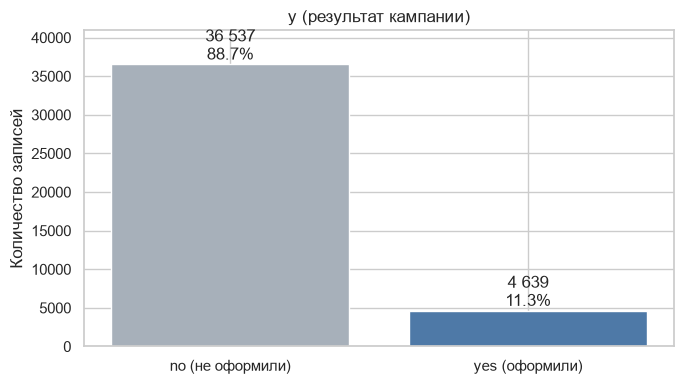

In [12]:
target_counts = df_clean["y"].value_counts().reindex(["no", "yes"])
target_share = (
    df_clean["y"].value_counts(normalize=True).reindex(["no", "yes"]) * 100
)

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    ["no (не оформили)", "yes (оформили)"],
    target_counts.values,
    color=[COLOR_NO, COLOR_YES]
)

for bar, count, share in zip(bars, target_counts.values, target_share.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(count):,}".replace(",", " ") + f"\n{share:.1f}%",
        ha="center",
        va="bottom"
    )

ax.set_title("y (результат кампании)")
ax.set_ylabel("Количество записей")
ax.set_ylim(0, target_counts.max() * 1.12)

plt.tight_layout()
plt.show()

Ответ "yes" встречается в 4 639 строках (11,3%), а "no" - в 36 537 (88,7%). Классы сильно несбалансированы. Поэтому одной accuracy для оценки модели недостаточно: модель может часто угадывать "no", но не находить клиентов с ответом "yes".

### 2.2. Распределения числовых признаков

На гистограммах представлены возраст, длительность разговора, число звонков в текущей кампании и количество прошлых контактов. `pdays` показывается отдельно, поскольку значение 999 имеет специальный смысл.

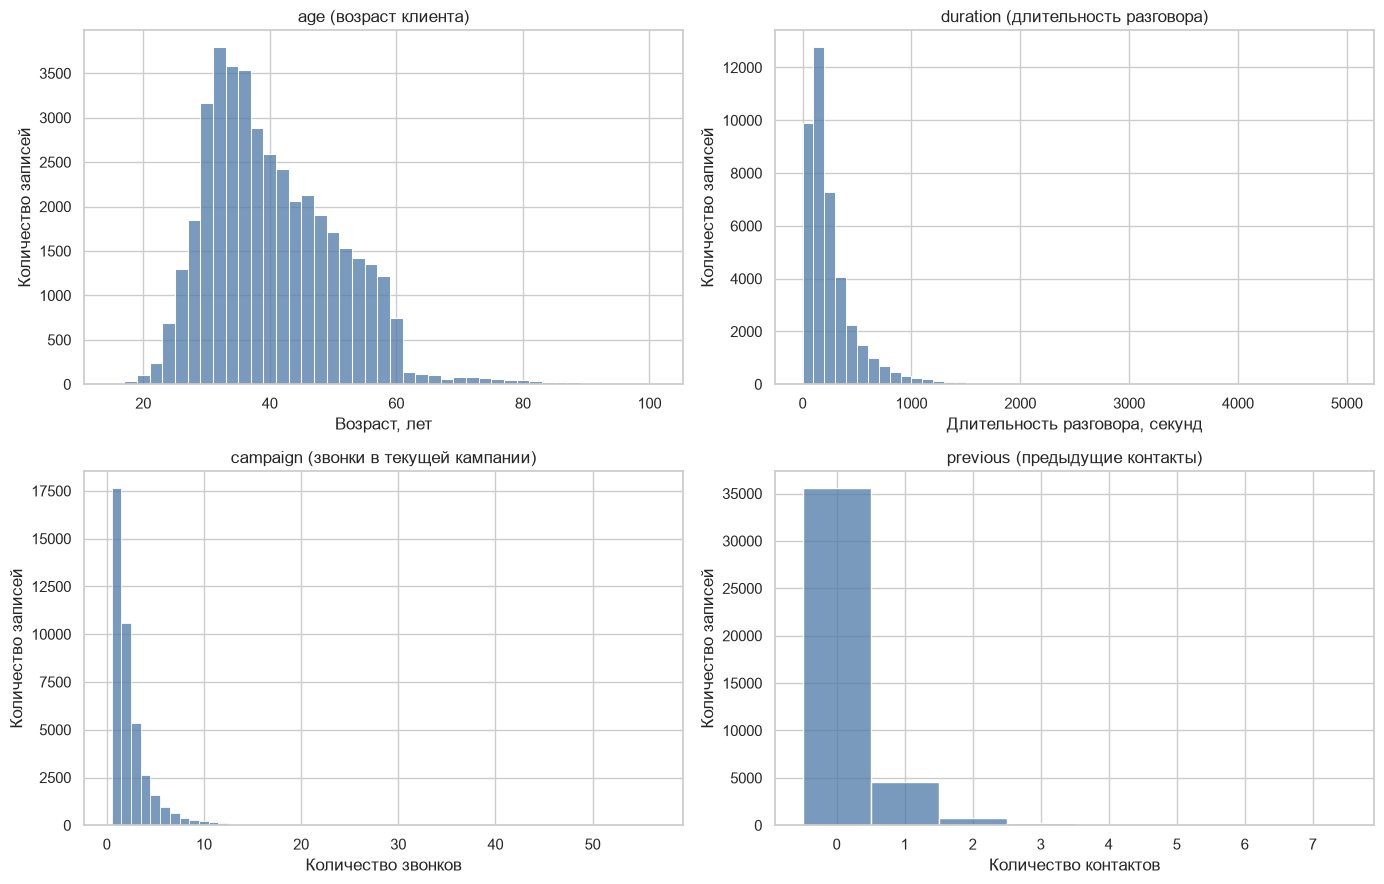

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

plots = [
    (
        "age",
        np.arange(15, 102, 2),
        "age (возраст клиента)",
        "Возраст, лет"
    ),
    (
        "duration",
        np.arange(0, 5001, 100),
        "duration (длительность разговора)",
        "Длительность разговора, секунд"
    ),
    (
        "campaign",
        np.arange(0.5, 57.5, 1),
        "campaign (звонки в текущей кампании)",
        "Количество звонков"
    ),
    (
        "previous",
        np.arange(-0.5, 8.5, 1),
        "previous (предыдущие контакты)",
        "Количество контактов"
    )
]

for ax, (column, bins, title, xlabel) in zip(axes.flat, plots):
    sns.histplot(
        data=df_clean,
        x=column,
        bins=bins,
        color=COLOR_MAIN,
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Количество записей")

plt.tight_layout()
plt.show()

У `duration`, `campaign` и `previous` заметен длинный правый хвост: большинство значений небольшие, но встречаются и большие. Экстремальное значение не считается ошибкой автоматически - сначала учитывается смысл признака.

### 2.3. Числовые признаки в группах "yes" и "no"

Распределения сравниваются по результату кампании. Boxplot показывает медиану и крайние наблюдения, но его "усы" не являются правилом для автоматического удаления данных.

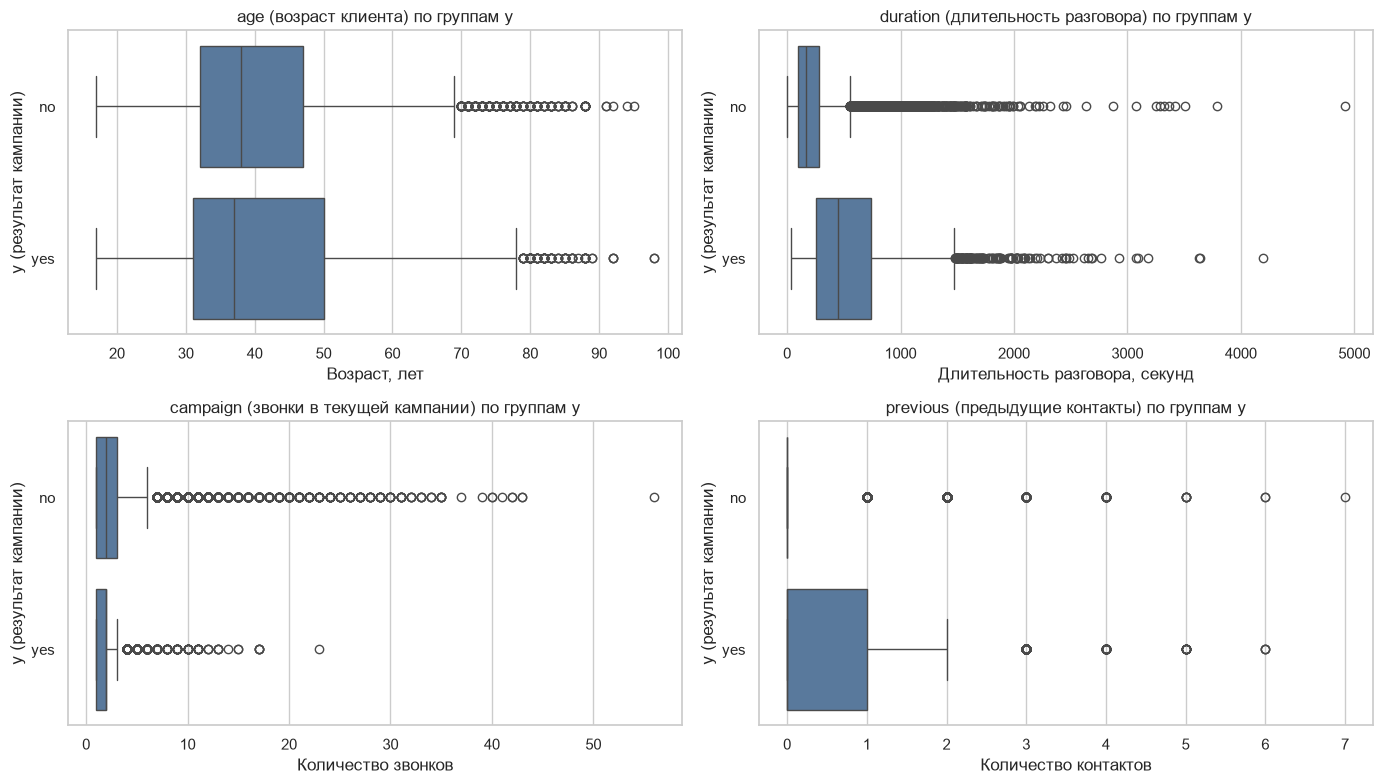

In [14]:
outlier_plots = [
    ("age", "возраст клиента", "Возраст, лет"),
    ("duration", "длительность разговора", "Длительность разговора, секунд"),
    ("campaign", "звонки в текущей кампании", "Количество звонков"),
    ("previous", "предыдущие контакты", "Количество контактов")
]

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for ax, (column, name, xlabel) in zip(axes.flat, outlier_plots):
    sns.boxplot(
        data=df_clean,
        x=column,
        y="y",
        order=["no", "yes"],
        color=COLOR_MAIN,
        showfliers=True,
        ax=ax
    )

    ax.set_title(f"{column} ({name}) по группам y")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("y (результат кампании)")

plt.tight_layout()
plt.show()

Распределения возраста в группах "yes" и "no" сильно перекрываются. У клиентов с ответом "yes" медиана длительности разговора выше, а число звонков `campaign` обычно ниже. Эти различия относятся к уже прошедшим контактам, поэтому `duration` и `campaign` исключаются из прогноза до начала текущей кампании.

# 3. Связи между признаками

_Вклад в проекте: DA1 - поиск связей между признаками и проверка особенностей данных._


Далее признаки рассматриваются совместно. Сначала анализируются канал связи и месяц, затем - связи между числовыми показателями.

### 3.1. Канал связи и месяц

Для `cellular` и `telephone` сравнивается доля ответов "yes" в разные месяцы. Количество наблюдений помогает оценить надежность процента в каждой группе.

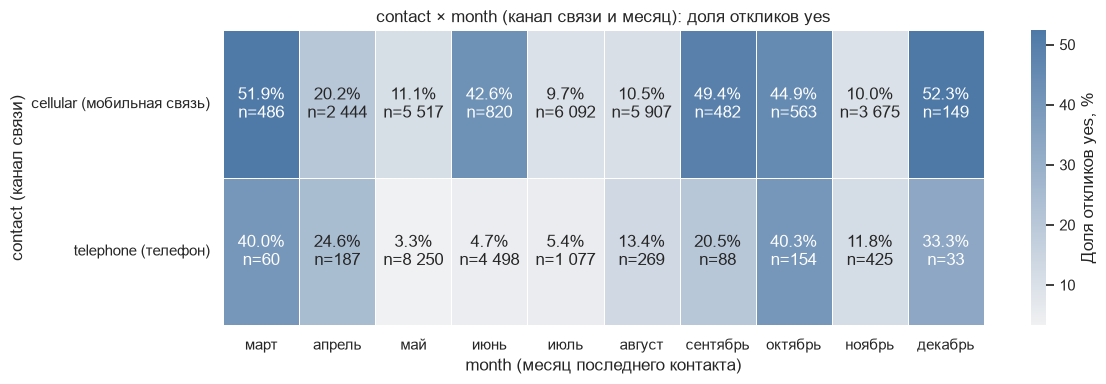

In [15]:
month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
month_labels = ["март", "апрель", "май", "июнь", "июль",
                "август", "сентябрь", "октябрь", "ноябрь", "декабрь"]
contact_order = ["cellular", "telephone"]

contact_month_summary = (
    df_clean.assign(is_yes=df_clean["y"].eq("yes").astype(int))
    .groupby(["contact", "month"], observed=True)
    .agg(
        contacts=("y", "size"),
        response_rate=("is_yes", "mean")
    )
    .reset_index()
)

rate_matrix = (
    contact_month_summary
    .pivot(index="contact", columns="month", values="response_rate")
    .reindex(index=contact_order, columns=month_order)
)

count_matrix = (
    contact_month_summary
    .pivot(index="contact", columns="month", values="contacts")
    .reindex(index=contact_order, columns=month_order)
)

rate_percent = rate_matrix * 100
annotations = np.empty(rate_matrix.shape, dtype=object)

for i in range(rate_matrix.shape[0]):
    for j in range(rate_matrix.shape[1]):
        rate = rate_matrix.iloc[i, j]
        count = count_matrix.iloc[i, j]

        if pd.isna(rate) or pd.isna(count):
            annotations[i, j] = ""
        else:
            annotations[i, j] = (
                f"{rate * 100:.1f}%\n"
                f"n={int(count):,}".replace(",", " ")
            )

rate_percent.index = [
    "cellular (мобильная связь)",
    "telephone (телефон)"
]
rate_percent.columns = month_labels

fig, ax = plt.subplots(figsize=(12, 4))

sns.heatmap(
    rate_percent,
    annot=annotations,
    fmt="",
    cmap=sns.light_palette(COLOR_MAIN, as_cmap=True),
    linewidths=0.5,
    cbar_kws={"label": "Доля откликов yes, %"},
    ax=ax
)

ax.set_title("contact × month (канал связи и месяц): доля откликов yes")
ax.set_xlabel("month (месяц последнего контакта)")
ax.set_ylabel("contact (канал связи)")

plt.tight_layout()
plt.show()

В большинстве месяцев доля "yes" при `cellular` выше, чем при `telephone`, но разница меняется от месяца к месяцу. В мае отклик низкий для обоих каналов. В отдельных месяцах наблюдений меньше, поэтому высокий процент нельзя напрямую сравнивать с показателем для большого месяца.

### 3.2. Корреляции числовых признаков

Для матрицы корреляций `y` кодируется как 0 для "no" и 1 для "yes". Матрица показывает линейные связи между числовыми показателями, но сама по себе не объясняет причину отклика.

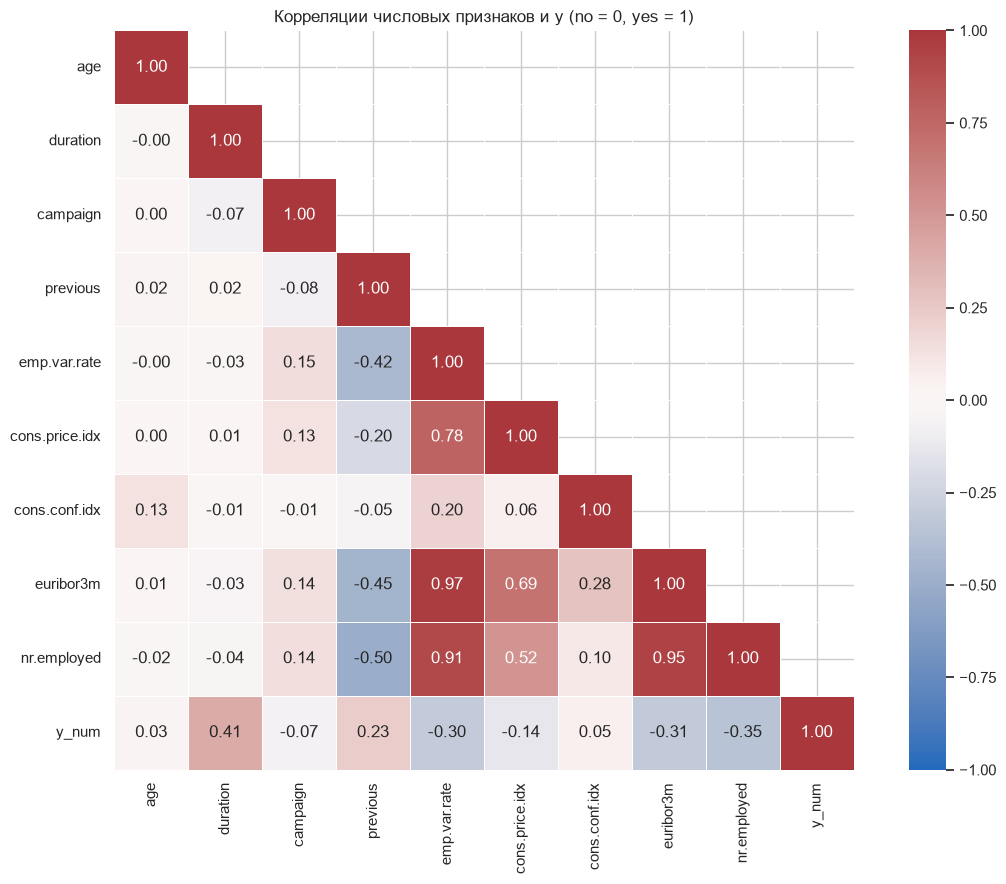

In [16]:
numeric_columns = [
    "age", "duration", "campaign", "previous",
    "emp.var.rate", "cons.price.idx", "cons.conf.idx",
    "euribor3m", "nr.employed"
]

corr_data = df_clean[numeric_columns].copy()
corr_data["y_num"] = (
    df_clean["y"]
    .map({"no": 0, "yes": 1})
    .astype("int8")
)

corr = corr_data.corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(12, 9))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    ax=ax
)

ax.set_title("Корреляции числовых признаков и y (no = 0, yes = 1)")

plt.tight_layout()
plt.show()

Сильнее всего связаны экономические показатели: корреляция `emp.var.rate` с `euribor3m` равна 0,97, а `euribor3m` с `nr.employed` - 0,95. Для логистической регрессии далее сравниваются варианты масштабирования и регуляризации.

# 4. История прошлых контактов

_Вклад в проекте: DA1 - анализ истории контактов и специальных значений._


Рассматривается связь прошлого опыта общения с текущим ответом. Отдельное внимание уделяется `pdays`: код 999 не является реальным числом дней.

### 4.1. Давность предыдущего контакта `pdays`

Строки со специальным кодом 999 выделяются отдельно, после чего рассматриваются реальные значения числа дней.

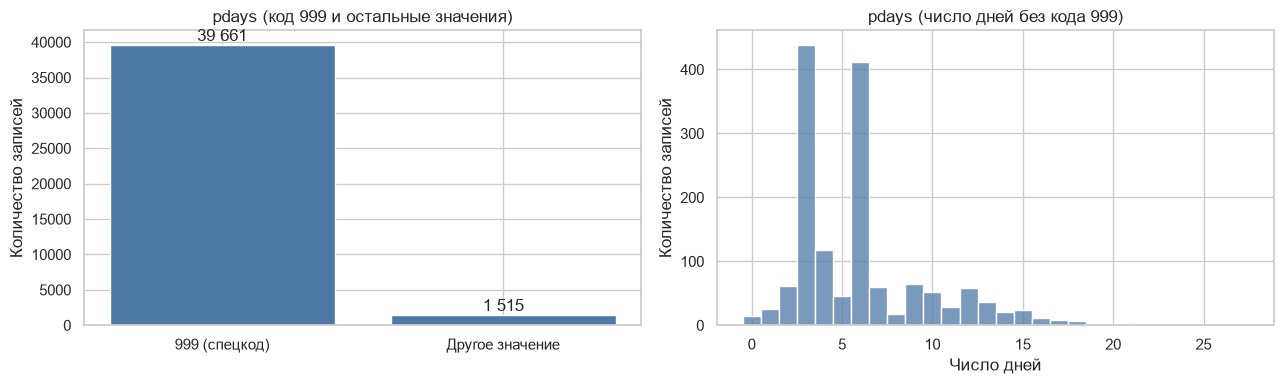

In [17]:
pdays_status = pd.Series(
    np.where(df_clean["pdays"] == 999, "999 (спецкод)", "Другое значение")
).value_counts().reindex(["999 (спецкод)", "Другое значение"])

pdays_real = df_clean.loc[df_clean["pdays"] != 999, "pdays"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

bars = axes[0].bar(
    pdays_status.index,
    pdays_status.values,
    color=COLOR_MAIN
)

for bar, count in zip(bars, pdays_status.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}".replace(",", " "),
        ha="center",
        va="bottom"
    )

axes[0].set_title("pdays (код 999 и остальные значения)")
axes[0].set_ylabel("Количество записей")

sns.histplot(
    x=pdays_real,
    discrete=True,
    color=COLOR_MAIN,
    ax=axes[1]
)

axes[1].set_title("pdays (число дней без кода 999)")
axes[1].set_xlabel("Число дней")
axes[1].set_ylabel("Количество записей")

plt.tight_layout()
plt.show()

На первом графике 999 показан отдельно от реальных сроков. Если трактовать этот код как обычное число, модель воспримет его как 999 дней между контактами.

# 5. Отклик по характеристикам клиента и контакта

_Вклад в проекте: DA2 - анализ отклика по клиентским сегментам и характеристикам контакта._


Сравнивается доля "yes" между группами. Учитывается не только процент, но и количество наблюдений: в небольших группах оценки менее устойчивы.

### 5.1. Профессия `job`

По профессиям сравниваются доля отклика и размер каждой группы.

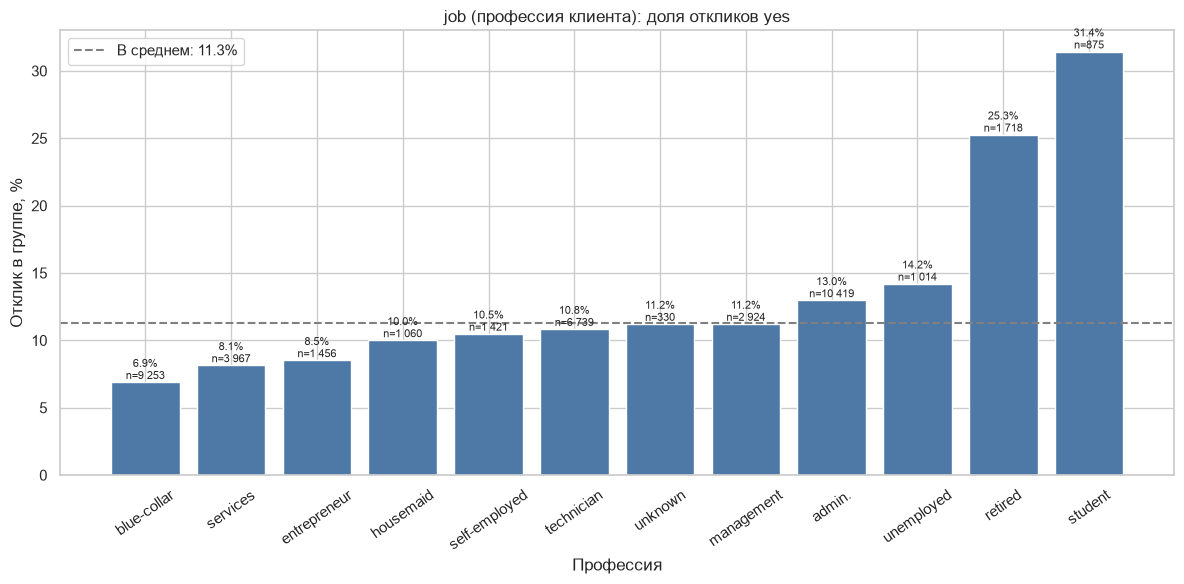

In [18]:
job_summary = (
    df_clean.assign(is_yes=df_clean["y"].eq("yes").astype(int))
    .groupby("job", observed=True)
    .agg(
        contacts=("y", "size"),
        response_rate=("is_yes", "mean")
    )
    .sort_values("response_rate")
)

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(
    job_summary.index.astype(str),
    job_summary["response_rate"] * 100,
    color=COLOR_MAIN
)

for bar, (_, row) in zip(bars, job_summary.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{row['response_rate'] * 100:.1f}%\nn={int(row['contacts']):,}".replace(",", " "),
        ha="center",
        va="bottom",
        fontsize=8
    )

overall_rate = df_clean["y"].eq("yes").mean() * 100
ax.axhline(
    overall_rate,
    color="gray",
    linestyle="--",
    label=f"В среднем: {overall_rate:.1f}%"
)

ax.set_title("job (профессия клиента): доля откликов yes")
ax.set_xlabel("Профессия")
ax.set_ylabel("Отклик в группе, %")
ax.tick_params(axis="x", rotation=35)
ax.legend()

plt.tight_layout()
plt.show()

Наибольшая доля отклика у студентов (31,4%) и пенсионеров (25,3%), у рабочих профессий она ниже среднего (6,9%). Группы различаются по размеру, поэтому эти проценты описывают выборку и не гарантируют такой же результат для каждого клиента.

### 5.2. Образование `education`

Рассматривается доля "yes" у клиентов с разным уровнем образования.

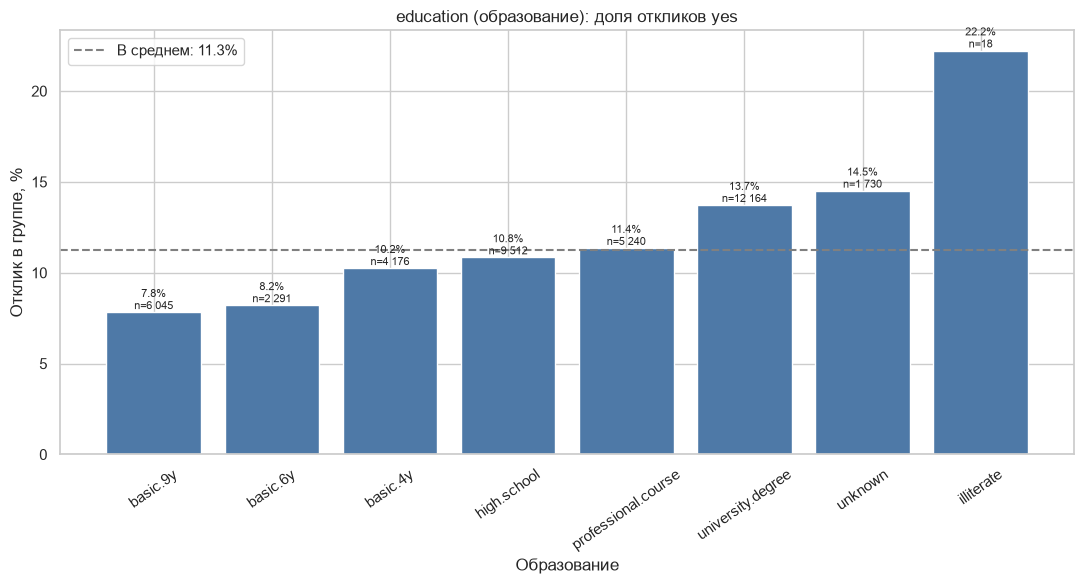

In [19]:
education_summary = (
    df_clean.assign(is_yes=df_clean["y"].eq("yes").astype(int))
    .groupby("education", observed=True)
    .agg(
        contacts=("y", "size"),
        response_rate=("is_yes", "mean")
    )
    .sort_values("response_rate")
)

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    education_summary.index.astype(str),
    education_summary["response_rate"] * 100,
    color=COLOR_MAIN
)

for bar, (_, row) in zip(bars, education_summary.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{row['response_rate'] * 100:.1f}%\nn={int(row['contacts']):,}".replace(",", " "),
        ha="center",
        va="bottom",
        fontsize=8
    )

overall_rate = df_clean["y"].eq("yes").mean() * 100
ax.axhline(
    overall_rate,
    color="gray",
    linestyle="--",
    label=f"В среднем: {overall_rate:.1f}%"
)

ax.set_title("education (образование): доля откликов yes")
ax.set_xlabel("Образование")
ax.set_ylabel("Отклик в группе, %")
ax.tick_params(axis="x", rotation=35)
ax.legend()

plt.tight_layout()
plt.show()

У категории `illiterate` доля отклика высокая, но в ней всего 18 контактов. По такой небольшой группе нельзя делать уверенный вывод. Среди крупных категорий отклик выше среднего у клиентов с высшим образованием.

### 5.3. Жилищный и личный кредит

`housing` и `loan` анализируются отдельно, поскольку обозначают разные виды кредита.

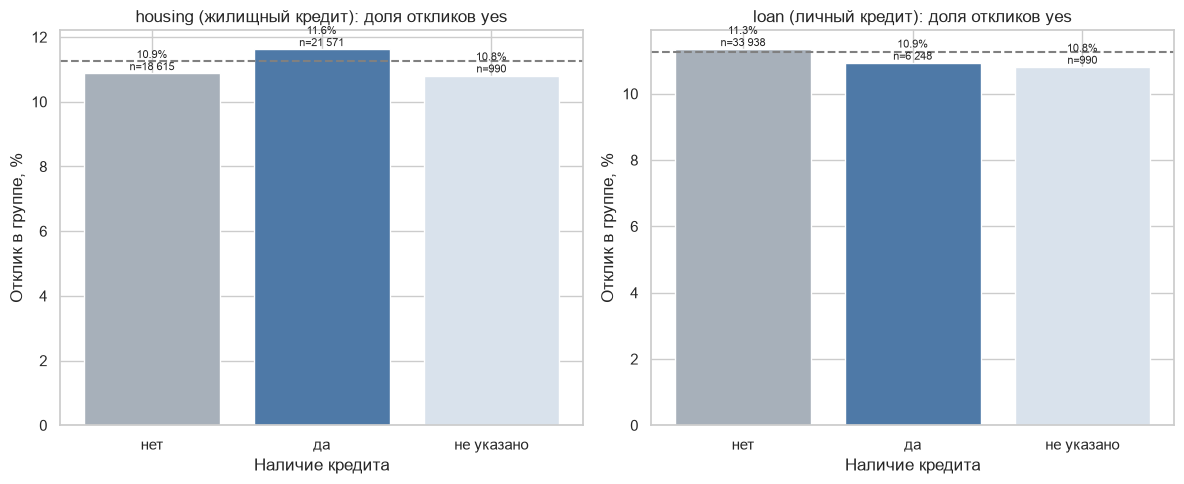

In [20]:
credit_columns = {
    "housing": "housing (жилищный кредит)",
    "loan": "loan (личный кредит)"
}

overall_rate = df_clean["y"].eq("yes").mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (column, title) in zip(axes, credit_columns.items()):
    summary = (
        df_clean.assign(is_yes=df_clean["y"].eq("yes").astype(int))
        .groupby(column, observed=True)
        .agg(
            contacts=("y", "size"),
            response_rate=("is_yes", "mean")
        )
        .reindex(["no", "yes", "unknown"])
    )

    bars = ax.bar(
        ["нет", "да", "не указано"],
        summary["response_rate"] * 100,
        color=[COLOR_NO, COLOR_YES, "#D9E2EC"]
    )

    for bar, (_, row) in zip(bars, summary.iterrows()):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{row['response_rate'] * 100:.1f}%\nn={int(row['contacts']):,}".replace(",", " "),
            ha="center",
            va="bottom",
            fontsize=8
        )

    ax.axhline(overall_rate, color="gray", linestyle="--")
    ax.set_title(f"{title}: доля откликов yes")
    ax.set_xlabel("Наличие кредита")
    ax.set_ylabel("Отклик в группе, %")

plt.tight_layout()
plt.show()

По жилищному кредиту доли близки: 11,6% у клиентов с кредитом и 10,9% без него. По личному кредиту разница еще меньше. На этих графиках заметной связи с откликом не видно.

### 5.4. Канал связи `contact`

Сравнивается доля отклика по мобильному и стационарному каналам связи.

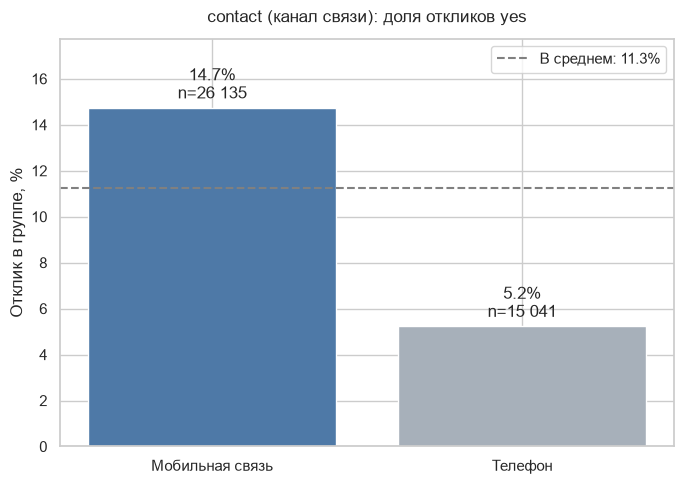

In [21]:
contact_summary = (
    df_clean.assign(is_yes=df_clean["y"].eq("yes").astype(int))
    .groupby("contact", observed=True)
    .agg(
        contacts=("y", "size"),
        response_rate=("is_yes", "mean")
    )
    .reindex(["cellular", "telephone"])
)

rates = contact_summary["response_rate"] * 100

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    ["Мобильная связь", "Телефон"],
    rates,
    color=["#4E79A7", "#A7B0BA"]
)

for bar, (_, row) in zip(bars, contact_summary.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        f"{row['response_rate'] * 100:.1f}%\nn={int(row['contacts']):,}".replace(",", " "),
        ha="center",
        va="bottom"
    )

overall_rate = df_clean["y"].eq("yes").mean() * 100
ax.axhline(
    overall_rate,
    color="gray",
    linestyle="--",
    label=f"В среднем: {overall_rate:.1f}%"
)

ax.set_ylim(0, rates.max() + 3)
ax.set_title("contact (канал связи): доля откликов yes", pad=12)
ax.set_ylabel("Отклик в группе, %")
ax.legend()

plt.tight_layout()
plt.show()

В этой выборке доля "yes" при `cellular` выше, чем при `telephone`: 14,7% против 5,2%. Это наблюдение проверяется в модели, но описательный график не доказывает, что разницу вызвал именно канал связи.

### 5.5. Месяц `month`

Для каждого месяца сравниваются доля отклика и количество контактов.

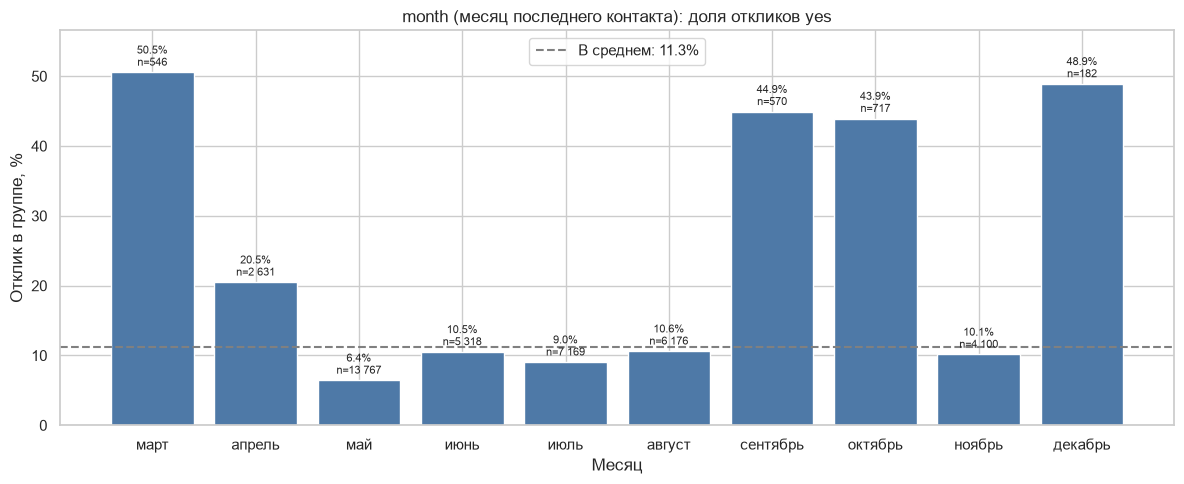

In [22]:
month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]

month_labels = {
    "mar": "март", "apr": "апрель", "may": "май", "jun": "июнь",
    "jul": "июль", "aug": "август", "sep": "сентябрь",
    "oct": "октябрь", "nov": "ноябрь", "dec": "декабрь"
}

month_summary = (
    df_clean.assign(is_yes=df_clean["y"].eq("yes").astype(int))
    .groupby("month", observed=True)
    .agg(
        contacts=("y", "size"),
        response_rate=("is_yes", "mean")
    )
    .reindex(month_order)
)

rates = month_summary["response_rate"] * 100
bars = None

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(
    [month_labels[m] for m in month_order],
    rates,
    color=COLOR_MAIN
)

for bar, (_, row) in zip(bars, month_summary.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{row['response_rate'] * 100:.1f}%\nn={int(row['contacts']):,}".replace(",", " "),
        ha="center",
        va="bottom",
        fontsize=8
    )

overall_rate = df_clean["y"].eq("yes").mean() * 100
ax.axhline(
    overall_rate,
    color="gray",
    linestyle="--",
    label=f"В среднем: {overall_rate:.1f}%"
)

ax.set_ylim(0, rates.max() + 6)
ax.set_title("month (месяц последнего контакта): доля откликов yes")
ax.set_xlabel("Месяц")
ax.set_ylabel("Отклик в группе, %")
ax.legend()

plt.tight_layout()
plt.show()

В марте и сентябре доли "yes" выше, но контактов там меньше, чем в мае. В мае наблюдений больше всего, а доля отклика ниже. Высокий процент поэтому не всегда означает большое число оформленных вкладов.

### 5.6. День недели `day_of_week`

Проверяется, насколько заметно меняется доля отклика в разные дни недели.

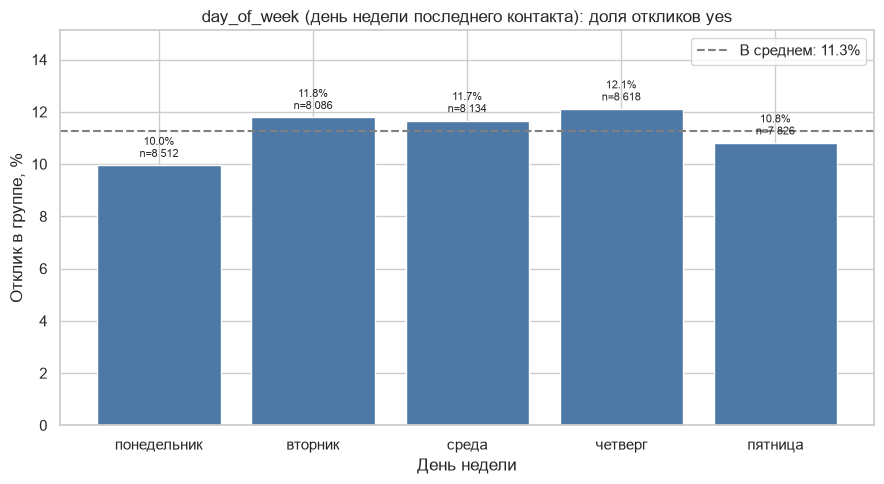

In [23]:
day_order = ["mon", "tue", "wed", "thu", "fri"]
day_labels = ["понедельник", "вторник", "среда", "четверг", "пятница"]

day_summary = (
    df_clean.assign(is_yes=df_clean["y"].eq("yes").astype(int))
    .groupby("day_of_week", observed=True)
    .agg(
        contacts=("y", "size"),
        response_rate=("is_yes", "mean")
    )
    .reindex(day_order)
)

rates = day_summary["response_rate"] * 100

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(day_labels, rates, color=COLOR_MAIN)

for bar, (_, row) in zip(bars, day_summary.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        f"{row['response_rate'] * 100:.1f}%\nn={int(row['contacts']):,}".replace(",", " "),
        ha="center",
        va="bottom",
        fontsize=8
    )

overall_rate = df_clean["y"].eq("yes").mean() * 100
ax.axhline(
    overall_rate,
    color="gray",
    linestyle="--",
    label=f"В среднем: {overall_rate:.1f}%"
)

ax.set_ylim(0, rates.max() + 3)
ax.set_title("day_of_week (день недели последнего контакта): доля откликов yes")
ax.set_xlabel("День недели")
ax.set_ylabel("Отклик в группе, %")
ax.legend()

plt.tight_layout()
plt.show()

Доли по дням недели находятся около среднего уровня и меняются от 10,0% до 12,1%. На этом графике явного различия между днями не видно.

# 6. Результаты прошлых кампаний

_Вклад в проекте: DA2 - анализ результатов прошлых кампаний и их связи с откликом._


Сравниваются текущий отклик, результат и количество прошлых контактов. Эти признаки относятся к прошлому и могут быть известны до новой кампании.

### 6.1. Результат прошлой кампании `poutcome`

Доля текущих ответов "yes" сравнивается для групп `success`, `failure` и `nonexistent`. Значение `success` рассматривается как отметка в исходных данных.

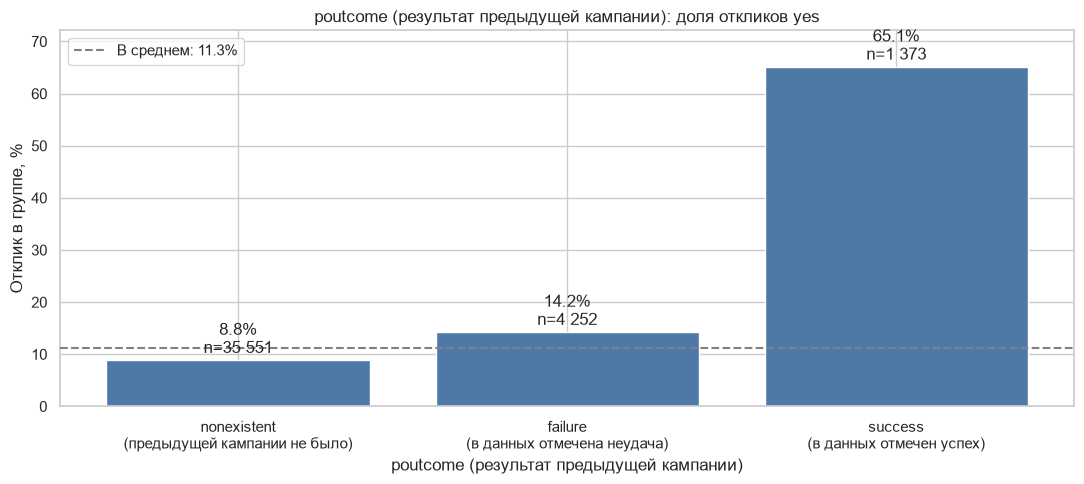

In [24]:
poutcome_order = ["nonexistent", "failure", "success"]

poutcome_labels = [
    "nonexistent\n(предыдущей кампании не было)",
    "failure\n(в данных отмечена неудача)",
    "success\n(в данных отмечен успех)"
]

poutcome_summary = (
    df_clean.assign(is_yes=df_clean["y"].eq("yes").astype(int))
    .groupby("poutcome", observed=True)
    .agg(
        contacts=("y", "size"),
        response_rate=("is_yes", "mean")
    )
    .reindex(poutcome_order)
)

rates = poutcome_summary["response_rate"] * 100

fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.bar(
    poutcome_labels,
    rates,
    color=COLOR_MAIN
)

for bar, (_, row) in zip(bars, poutcome_summary.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{row['response_rate'] * 100:.1f}%\n"
        f"n={int(row['contacts']):,}".replace(",", " "),
        ha="center",
        va="bottom",
        zorder=4
    )

overall_rate = df_clean["y"].eq("yes").mean() * 100

ax.axhline(
    overall_rate,
    color="gray",
    linestyle="--",
    label=f"В среднем: {overall_rate:.1f}%",
    zorder=3
)

ax.set_ylim(0, rates.max() + 7)
ax.set_title("poutcome (результат предыдущей кампании): доля откликов yes")
ax.set_xlabel("poutcome (результат предыдущей кампании)")
ax.set_ylabel("Отклик в группе, %")
ax.legend()

plt.tight_layout()
plt.show()

У клиентов с `poutcome = success` доля текущих ответов "yes" составила 65,1%; после `failure` - 14,2%; при `nonexistent` - 8,8%. Признак может быть полезен для прогноза, поскольку описывает предыдущую кампанию.

### 6.2. Количество прошлых контактов `previous`

Проверяется, меняется ли отклик в зависимости от числа контактов до текущей кампании. Редкие большие значения объединяются в одну группу.

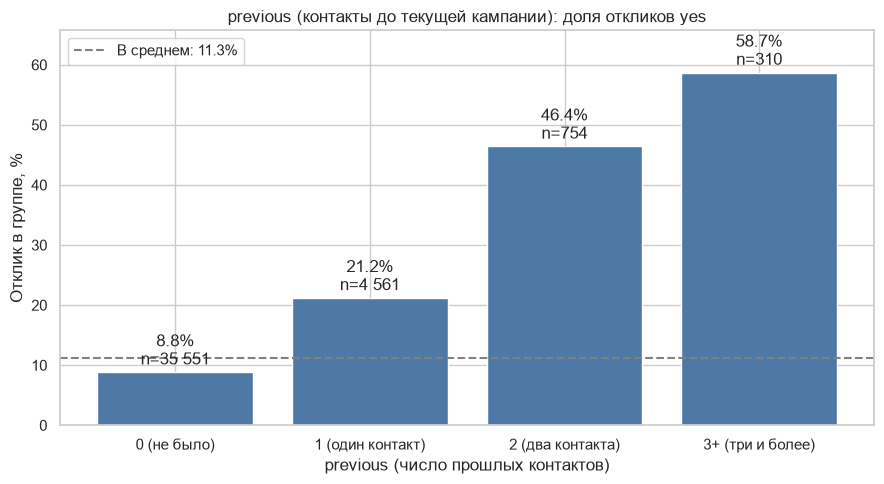

In [25]:
previous_order = ["0", "1", "2", "3+"]
previous_labels = [
    "0 (не было)",
    "1 (один контакт)",
    "2 (два контакта)",
    "3+ (три и более)"
]

previous_summary = (
    df_clean.assign(
        is_yes=df_clean["y"].eq("yes").astype(int),
        previous_group=df_clean["previous"].map(
            lambda value: "3+" if value >= 3 else str(value)
        )
    )
    .groupby("previous_group", observed=True)
    .agg(
        contacts=("y", "size"),
        response_rate=("is_yes", "mean")
    )
    .reindex(previous_order)
)

rates = previous_summary["response_rate"] * 100

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(previous_labels, rates, color=COLOR_MAIN)

for bar, (_, row) in zip(bars, previous_summary.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{row['response_rate'] * 100:.1f}%\nn={int(row['contacts']):,}".replace(",", " "),
        ha="center",
        va="bottom"
    )

overall_rate = df_clean["y"].eq("yes").mean() * 100
ax.axhline(
    overall_rate,
    color="gray",
    linestyle="--",
    label=f"В среднем: {overall_rate:.1f}%"
)

ax.set_ylim(0, rates.max() + 7)
ax.set_title("previous (контакты до текущей кампании): доля откликов yes")
ax.set_xlabel("previous (число прошлых контактов)")
ax.set_ylabel("Отклик в группе, %")
ax.legend()

plt.tight_layout()
plt.show()

Доля "yes" растет вместе с числом прошлых контактов: от 8,8% при `previous = 0` до 58,7% при трех и более. Последние группы небольшие, поэтому это наблюдение рассматривается как гипотеза, а не как причинное объяснение.

### 6.3. Давность прошлого контакта `pdays`

Сравнивается доля отклика для клиентов без реального значения `pdays` и для групп с разной давностью контакта.

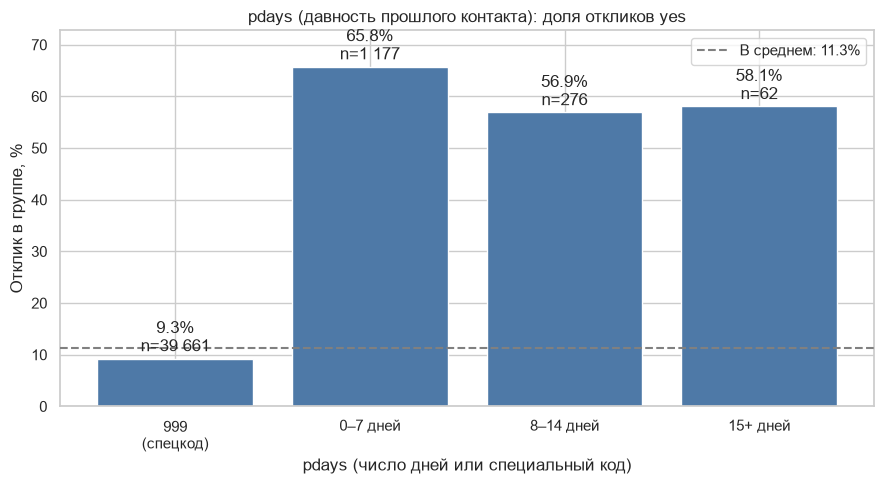

In [26]:
def group_pdays(value):
    if value == 999:
        return "999"
    elif value <= 7:
        return "0–7"
    elif value <= 14:
        return "8–14"
    else:
        return "15+"

pdays_order = ["999", "0–7", "8–14", "15+"]
pdays_labels = [
    "999\n(спецкод)",
    "0–7 дней",
    "8–14 дней",
    "15+ дней"
]

pdays_summary = (
    df_clean.assign(
        is_yes=df_clean["y"].eq("yes").astype(int),
        pdays_group=df_clean["pdays"].map(group_pdays)
    )
    .groupby("pdays_group", observed=True)
    .agg(
        contacts=("y", "size"),
        response_rate=("is_yes", "mean")
    )
    .reindex(pdays_order)
)

rates = pdays_summary["response_rate"] * 100

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(pdays_labels, rates, color=COLOR_MAIN)

for bar, (_, row) in zip(bars, pdays_summary.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{row['response_rate'] * 100:.1f}%\nn={int(row['contacts']):,}".replace(",", " "),
        ha="center",
        va="bottom",
        zorder=4
    )

overall_rate = df_clean["y"].eq("yes").mean() * 100
ax.axhline(
    overall_rate,
    color="gray",
    linestyle="--",
    label=f"В среднем: {overall_rate:.1f}%",
    zorder=3
)

ax.set_ylim(0, rates.max() + 7)
ax.set_title("pdays (давность прошлого контакта): доля откликов yes")
ax.set_xlabel("pdays (число дней или специальный код)")
ax.set_ylabel("Отклик в группе, %")
ax.legend()

plt.tight_layout()
plt.show()

При `pdays = 999` доля "yes" ниже среднего. В группах с реальным числом дней доли выше, но таких наблюдений меньше. Поэтому специальный код отделяется от числа дней при подготовке признаков.

# 7. Число звонков в текущей кампании

_Вклад в проекте: DA2 - анализ эффективности контактов по числу звонков и времени кампании._


Рассматривается изменение отклика с числом звонков клиенту в текущей кампании. Этот разрез полезен для EDA, но не подходит для прогноза до начала кампании.

### 7.1. `campaign`

Редкие большие значения объединяются; на графике показан размер каждой группы.

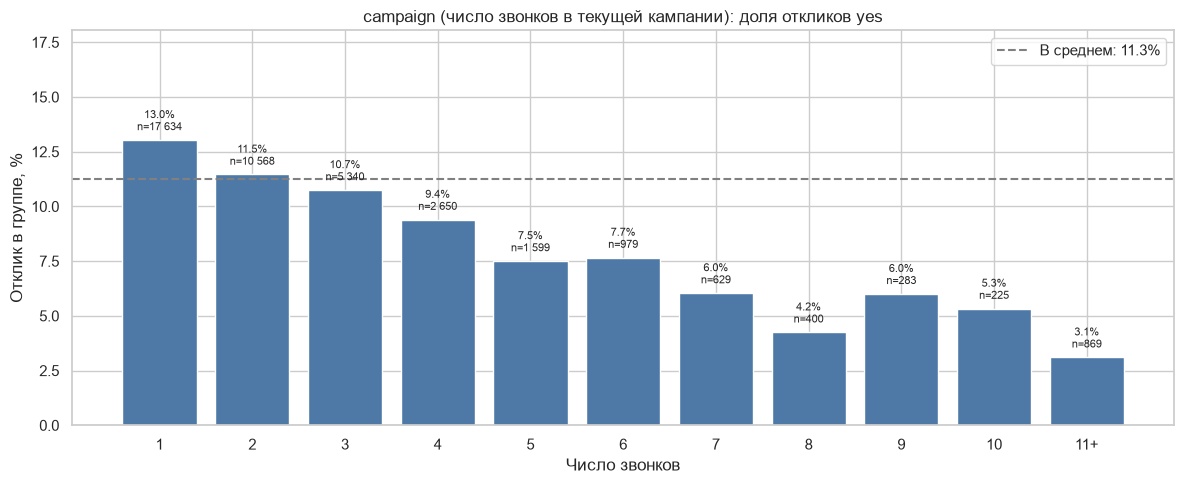

In [27]:
campaign_order = [str(n) for n in range(1, 11)] + ["11+"]

campaign_summary = (
    df_clean.assign(
        is_yes=df_clean["y"].eq("yes").astype(int),
        campaign_group=df_clean["campaign"].map(
            lambda value: str(value) if value <= 10 else "11+"
        )
    )
    .groupby("campaign_group", observed=True)
    .agg(
        contacts=("y", "size"),
        response_rate=("is_yes", "mean")
    )
    .reindex(campaign_order)
)

rates = campaign_summary["response_rate"] * 100

fig, ax = plt.subplots(figsize=(12, 5))

bars = ax.bar(campaign_order, rates, color=COLOR_MAIN)

for bar, (_, row) in zip(bars, campaign_summary.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f"{row['response_rate'] * 100:.1f}%\nn={int(row['contacts']):,}".replace(",", " "),
        ha="center",
        va="bottom",
        fontsize=8
    )

overall_rate = df_clean["y"].eq("yes").mean() * 100
ax.axhline(
    overall_rate,
    color="gray",
    linestyle="--",
    label=f"В среднем: {overall_rate:.1f}%"
)

ax.set_ylim(0, rates.max() + 5)
ax.set_title("campaign (число звонков в текущей кампании): доля откликов yes")
ax.set_xlabel("Число звонков")
ax.set_ylabel("Отклик в группе, %")
ax.legend()

plt.tight_layout()
plt.show()

В целом доля "yes" снижается с ростом числа звонков: от 13,0% при одном звонке до 3,1% в группе 11+. Снижение не строгое, а в редких группах проценты сильнее колеблются.

# 8. Портрет клиента

_Вклад в проекте: DA2 - формирование портрета откликающегося клиента._


Сравнивается отклик по возрасту, семейному положению и наличию просрочки. При интерпретации также учитывается размер групп.

### 8.1. Возраст `age`

Возраст объединяется в диапазоны, чтобы сравнить долю отклика между возрастными группами.

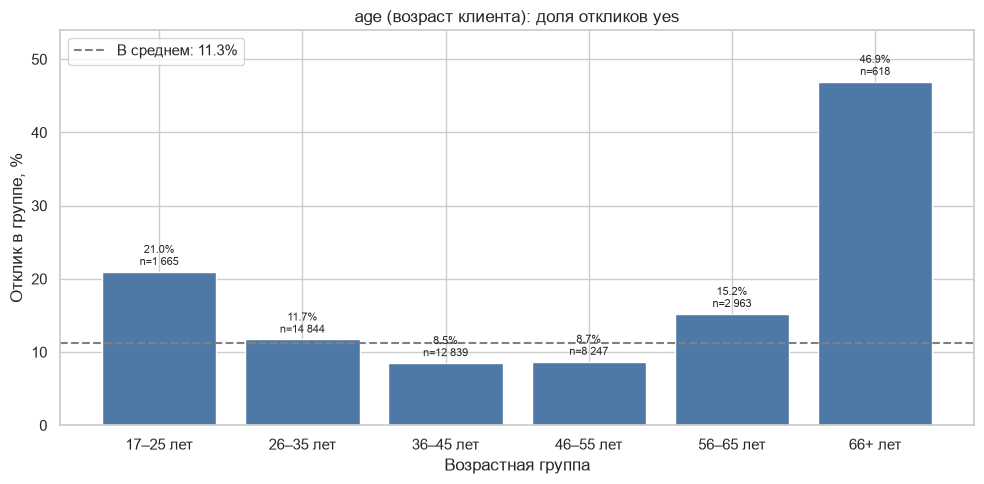

In [28]:
age_bins = [16, 25, 35, 45, 55, 65, 99]
age_labels = [
    "17–25 лет",
    "26–35 лет",
    "36–45 лет",
    "46–55 лет",
    "56–65 лет",
    "66+ лет"
]

age_summary = (
    df_clean.assign(
        is_yes=df_clean["y"].eq("yes").astype(int),
        age_group=pd.cut(
            df_clean["age"],
            bins=age_bins,
            labels=age_labels,
            include_lowest=True
        )
    )
    .groupby("age_group", observed=True)
    .agg(
        contacts=("y", "size"),
        response_rate=("is_yes", "mean")
    )
    .reindex(age_labels)
)

rates = age_summary["response_rate"] * 100

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(age_labels, rates, color=COLOR_MAIN)

for bar, (_, row) in zip(bars, age_summary.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{row['response_rate'] * 100:.1f}%\nn={int(row['contacts']):,}".replace(",", " "),
        ha="center",
        va="bottom",
        fontsize=8
    )

overall_rate = df_clean["y"].eq("yes").mean() * 100
ax.axhline(
    overall_rate,
    color="gray",
    linestyle="--",
    label=f"В среднем: {overall_rate:.1f}%"
)

ax.set_ylim(0, rates.max() + 7)
ax.set_title("age (возраст клиента): доля откликов yes")
ax.set_xlabel("Возрастная группа")
ax.set_ylabel("Отклик в группе, %")
ax.legend()

plt.tight_layout()
plt.show()

Доля отклика выше в группах 17-25 лет и 66+. В группе 66+ наблюдений меньше, чем в большинстве остальных возрастов. Общего равномерного роста отклика с возрастом не видно.

### 8.2. Семейное положение `marital`

Доля "yes" сравнивается по семейному положению.

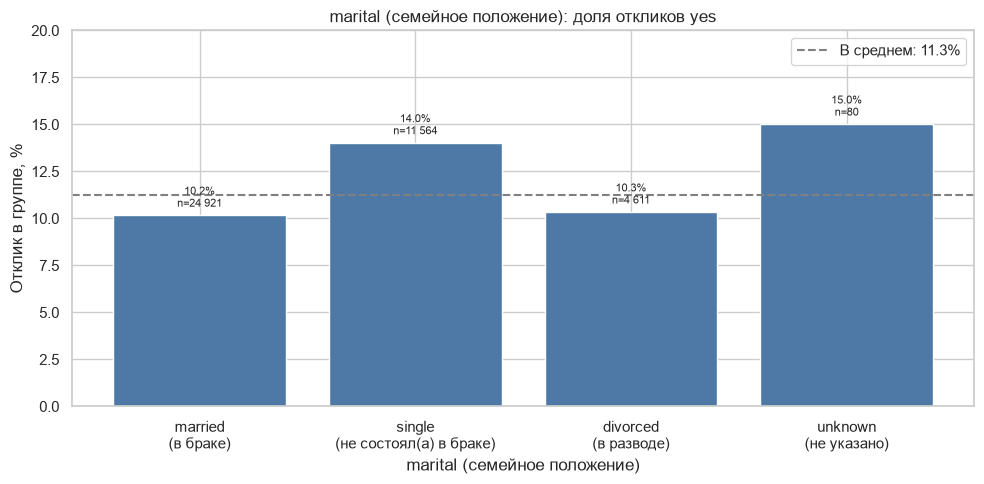

In [29]:
marital_order = ["married", "single", "divorced", "unknown"]

marital_labels = [
    "married\n(в браке)",
    "single\n(не состоял(а) в браке)",
    "divorced\n(в разводе)",
    "unknown\n(не указано)"
]

marital_summary = (
    df_clean.assign(is_yes=df_clean["y"].eq("yes").astype(int))
    .groupby("marital", observed=True)
    .agg(
        contacts=("y", "size"),
        response_rate=("is_yes", "mean")
    )
    .reindex(marital_order)
)

rates = marital_summary["response_rate"] * 100

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(marital_labels, rates, color=COLOR_MAIN)

for bar, (_, row) in zip(bars, marital_summary.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f"{row['response_rate'] * 100:.1f}%\nn={int(row['contacts']):,}".replace(",", " "),
        ha="center",
        va="bottom",
        fontsize=8
    )

overall_rate = df_clean["y"].eq("yes").mean() * 100
ax.axhline(
    overall_rate,
    color="gray",
    linestyle="--",
    label=f"В среднем: {overall_rate:.1f}%"
)

ax.set_ylim(0, rates.max() + 5)
ax.set_title("marital (семейное положение): доля откликов yes")
ax.set_xlabel("marital (семейное положение)")
ax.set_ylabel("Отклик в группе, %")
ax.legend()

plt.tight_layout()
plt.show()

У клиентов, не состоящих в браке, доля "yes" - 14,0%, у состоящих в браке и разведенных - около 10%. В категории `unknown` наблюдений мало, поэтому результат для нее рассматривается осторожно.

### 8.3. Просрочка по кредиту `default`

Рассматривается отклик в группах `no`, `yes` и `unknown`. Для каждой группы проверяется количество клиентов.

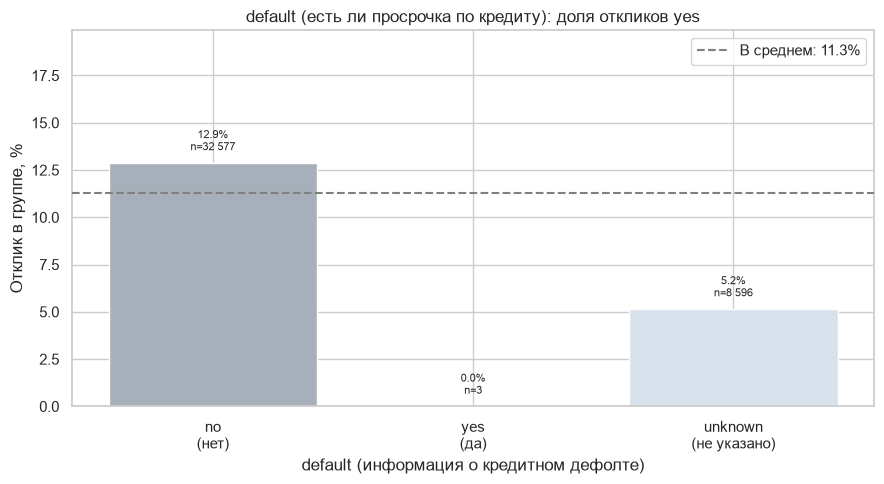

In [30]:
default_order = ["no", "yes", "unknown"]
default_labels = [
    "no\n(нет)",
    "yes\n(да)",
    "unknown\n(не указано)"
]

default_summary = (
    df_clean.assign(is_yes=df_clean["y"].eq("yes").astype(int))
    .groupby("default", observed=True)
    .agg(
        contacts=("y", "size"),
        response_rate=("is_yes", "mean")
    )
    .reindex(default_order)
)

rates = default_summary["response_rate"] * 100

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    default_labels,
    rates,
    color=[COLOR_NO, COLOR_YES, "#D9E2EC"]
)

for bar, (_, row) in zip(bars, default_summary.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{row['response_rate'] * 100:.1f}%\nn={int(row['contacts']):,}".replace(",", " "),
        ha="center",
        va="bottom",
        fontsize=8,
        zorder=4
    )

overall_rate = df_clean["y"].eq("yes").mean() * 100
ax.axhline(
    overall_rate,
    color="gray",
    linestyle="--",
    label=f"В среднем: {overall_rate:.1f}%",
    zorder=3
)

ax.set_ylim(0, rates.max() + 7)
ax.set_title("default (есть ли просрочка по кредиту): доля откликов yes")
ax.set_xlabel("default (информация о кредитном дефолте)")
ax.set_ylabel("Отклик в группе, %")
ax.legend()

plt.tight_layout()
plt.show()

В группе `default = yes` всего три контакта. По такому числу наблюдений нельзя оценить связь с оформлением вклада. Этот признак сохраняется в данных, но результат для группы не используется для сильных выводов.

# 9. Признаки для прогноза

_Вклад в проекте: DA1 - проверка доступности признаков и риска утечки; DA2 - постановка прогноза до начала кампании._


Прогноз строится до первого звонка в текущей кампании. Поэтому `duration` и `campaign` исключаются: длительность становится известна во время разговора, а число звонков накапливается по ходу кампании. Запланированные `contact`, `month` и `day_of_week` включаются, поскольку в этой постановке они считаются известными при выборе клиентов.

Для `pdays = 999` создается отдельный признак, чтобы не трактовать 999 как число дней. Категория `unknown` сохраняется отдельно: пустых ячеек в исходных данных нет.

# 10. Итог EDA и гипотезы

_Вклад в проекте: DA1 и DA2 - формулировка гипотез на основе EDA и выбор признаков для ML._


По результатам EDA сформулированы наблюдения для проверки в модели:
- `poutcome` может быть полезен: доля отклика выше после успешной прошлой кампании.
- `previous` и `pdays` могут помочь отличить клиентов без прошлых контактов от клиентов с историей.
- Доля отклика различается по каналу связи и месяцу; в модели проверяется, сохраняются ли эти различия при совместном учете признаков.
- Экономические показатели сильно связаны между собой, поэтому для логистической регрессии сравниваются масштабирование и регуляризация.

`duration` и `campaign` в модель не включаются, поскольку эти сведения становятся известны в ходе текущей кампании.

# 11. Обучение и сравнение моделей

_Вклад в проекте: ML1 и ML2 - подготовка модельного эксперимента, обучение и оценка моделей._


Проверяется, помогают ли выбранные признаки предсказывать ответ "yes". Основная метрика - PR-AUC: при небольшой доле ответов "yes" важно оценить, насколько хорошо модель находит положительный класс.

### 11.1. Подготовка признаков и разбиение

Целевая переменная отделяется от признаков. Формируются исходный и дополненный наборы признаков для проверки гипотезы о `pdays`. Затем строки делятся на обучающую и тестовую выборки в пропорции 80/20. `stratify` сохраняет одинаковую долю "yes" в обеих частях, а тестовая выборка не используется при настройке.

In [31]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, PrecisionRecallDisplay,
    ConfusionMatrixDisplay, classification_report
)

model_data = df_clean.copy()
y = model_data["y"].astype(str).eq("yes").astype("int8")

# Значение 999 в pdays является специальным кодом, поэтому оно отделяется от реального числа дней.
X_base = model_data.drop(columns=["y", "duration", "campaign", "pdays"]).copy()
X = X_base.copy()
X["pdays_is_999"] = model_data["pdays"].eq(999).astype("int8")
X["pdays_clean"] = model_data["pdays"].where(model_data["pdays"] != 999, np.nan)
X["had_previous_contacts"] = model_data["previous"].gt(0).astype("int8")

# OneHotEncoder получает категории как строки.
for column in X.select_dtypes(include=["category"]).columns:
    X[column] = X[column].astype("object")
    X_base[column] = X_base[column].astype("object")

train_idx, test_idx = train_test_split(
    np.arange(len(y)),
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()
X_train_base = X_base.iloc[train_idx].copy()
X_test_base = X_base.iloc[test_idx].copy()
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Строк в обучающей выборке:", len(X_train))
print("Строк в тестовой выборке:", len(X_test))
print("Доля yes в обучающей выборке:", round(y_train.mean(), 3))
print("Доля yes в тестовой выборке:", round(y_test.mean(), 3))

Строк в обучающей выборке: 32940
Строк в тестовой выборке: 8236
Доля yes в обучающей выборке: 0.113
Доля yes в тестовой выборке: 0.113


В обеих выборках доля ответов "yes" составляет около 11%, поэтому исходный баланс классов сохранен. Все следующие сравнения моделей выполняются на одних и тех же строках.

### 11.2. Бейзлайн

Сначала строится `DummyClassifier`, который всегда предсказывает самый частый класс. Это точка отсчета для сравнения. Если более сложные модели не превосходят бейзлайн по PR-AUC, выбранные признаки не дают полезного прогноза.

In [32]:
baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(X_train, y_train)
baseline_pred = baseline_model.predict(X_test)
baseline_scores = baseline_model.predict_proba(X_test)[:, 1]

baseline_metrics = {
    "Модель": "Бейзлайн",
    "Accuracy": accuracy_score(y_test, baseline_pred),
    "Precision yes": precision_score(y_test, baseline_pred, zero_division=0),
    "Recall yes": recall_score(y_test, baseline_pred, zero_division=0),
    "F1 yes": f1_score(y_test, baseline_pred, zero_division=0),
    "PR-AUC": average_precision_score(y_test, baseline_scores),
}
display(pd.DataFrame([baseline_metrics]).round(3))

     Модель  Accuracy  Precision yes  Recall yes  F1 yes  PR-AUC
0  Бейзлайн     0.887            0.0         0.0     0.0   0.113

Бейзлайн показывает высокую accuracy, потому что почти всем клиентам отвечает "no", но не находит ни одного клиента с "yes". Его PR-AUC примерно равна доле положительного класса и служит минимальным ориентиром для моделей.

### 11.3. Проверка созданных признаков

Проверяется гипотеза: если код 999 отделить от реальных дней, а наличие прошлых контактов показать отдельными признаками, модели будет проще использовать историю. Для проверки логистическая регрессия оценивается на исходном и дополненном наборах признаков с одинаковым разбиением на 5 фолдов.

In [33]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def make_preprocessor(data_sample, scaler):
    numeric_features = data_sample.select_dtypes(include=["number"]).columns.tolist()
    categorical_features = data_sample.select_dtypes(
        include=["object", "category", "string"]
    ).columns.tolist()

    numeric_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", scaler),
    ])
    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer(transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
    ])

def make_logistic_pipeline(data_sample, scaler):
    return Pipeline(steps=[
        ("preprocessor", make_preprocessor(data_sample, scaler)),
        ("classifier", LogisticRegression(
            C=1.0,
            class_weight="balanced",
            max_iter=1000,
            solver="liblinear",
            random_state=42
        )),
    ])

feature_rows = []
feature_variants = [
    ("Логистическая регрессия", "Без новых признаков", X_train_base, "logistic"),
    ("Логистическая регрессия", "С признаками истории контактов", X_train, "logistic"),
]

for model_name, variant_name, data, model_type in feature_variants:
    if model_type == "logistic":
        estimator = make_logistic_pipeline(data, StandardScaler())
    else:
        estimator = Pipeline(steps=[
            ("preprocessor", make_preprocessor(data, "passthrough")),
            ("classifier", RandomForestClassifier(
                n_estimators=30,
                max_depth=16,
                min_samples_leaf=5,
                random_state=42,
                n_jobs=1,
            )),
        ])
    scores = cross_validate(
        estimator,
        data,
        y_train,
        cv=cv,
        scoring="average_precision",
        n_jobs=1,
        return_train_score=False,
    )["test_score"]
    feature_rows.append({
        "Модель": model_name,
        "Набор признаков": variant_name,
        "PR-AUC среднее": scores.mean(),
        "PR-AUC стандартное отклонение": scores.std(),
    })

feature_comparison = pd.DataFrame(feature_rows).set_index(["Модель", "Набор признаков"])
display(feature_comparison.round(3))

                                                        PR-AUC среднее  PR-AUC стандартное отклонение
Модель                  Набор признаков                                                              
Логистическая регрессия Без новых признаков                      0.446                          0.014
                        С признаками истории контактов           0.444                          0.013

В таблице сопоставлены результаты для исходного и дополненного наборов признаков. Новые признаки не дали заметной прибавки к PR-AUC по сравнению с разбросом между фолдами, поэтому итоговое обучение проводится на более простом наборе. Проверка гипотезы остается в таблице.

### 11.4. Логистическая регрессия: масштабирование и подбор параметров

Масштаб признаков влияет на обучение логистической регрессии. В одном поиске сравниваются `StandardScaler` и вариант без масштабирования, а также сила регуляризации `C` и `class_weight`. Все варианты оцениваются по PR-AUC на одинаковых 5 фолдах.

In [34]:
logistic_pipeline = make_logistic_pipeline(X_train_base, StandardScaler())
logistic_grid = {
    "preprocessor__num__scaler": [StandardScaler(), "passthrough"],
    "classifier__C": [0.1, 1.0, 10.0],
    "classifier__class_weight": [None, "balanced"],
}

logistic_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_grid,
    scoring="average_precision",
    cv=cv,
    refit=True,
    n_jobs=1,
    return_train_score=False,
)
logistic_search.fit(X_train, y_train)
logistic_model = logistic_search.best_estimator_

print("Лучшие параметры:", logistic_search.best_params_)
print(
    "Средняя PR-AUC на кросс-валидации:",
    round(logistic_search.best_score_, 3),
    "+/-",
    round(logistic_search.cv_results_["std_test_score"][logistic_search.best_index_], 3),
)

Лучшие параметры: {'classifier__C': 1.0, 'classifier__class_weight': None, 'preprocessor__num__scaler': StandardScaler()}
Средняя PR-AUC на кросс-валидации: 0.449 +/- 0.015


Для отдельной оценки влияния масштабирования фиксируются одинаковые `C` и `class_weight` - лучшие значения из общего поиска. Поэтому в таблице меняется только масштабирование. Для числовых признаков приводятся средний и максимальный абсолютные коэффициенты; число коэффициентов остается тем же, поскольку кодирование категорий не меняется.

In [35]:
cv_results_lr = pd.DataFrame(logistic_search.cv_results_)
fixed_c = logistic_search.best_params_["classifier__C"]
fixed_class_weight = logistic_search.best_params_["classifier__class_weight"]
scale_rows = []

for scale_name, scaler in [("StandardScaler", StandardScaler()), ("Без масштабирования", "passthrough")]:
    matching_rows = cv_results_lr[
        cv_results_lr["params"].apply(
            lambda params: (
                params["classifier__C"] == fixed_c
                and params["classifier__class_weight"] == fixed_class_weight
                and (
                    isinstance(params["preprocessor__num__scaler"], StandardScaler)
                    if isinstance(scaler, StandardScaler)
                    else params["preprocessor__num__scaler"] == "passthrough"
                )
            )
        )
    ]
    row = matching_rows.iloc[0]
    comparison_model = clone(logistic_pipeline).set_params(
        preprocessor__num__scaler=scaler,
        classifier__C=fixed_c,
        classifier__class_weight=fixed_class_weight,
    )
    comparison_model.fit(X_train_base, y_train)

    names = comparison_model.named_steps["preprocessor"].get_feature_names_out()
    coefficients = comparison_model.named_steps["classifier"].coef_.ravel()
    numeric_mask = np.array([name.startswith("num__") for name in names])
    numeric_coefficients = np.abs(coefficients[numeric_mask])

    scale_rows.append({
        "Масштабирование": scale_name,
        "PR-AUC среднее": row["mean_test_score"],
        "PR-AUC стандартное отклонение": row["std_test_score"],
        "C": fixed_c,
        "class_weight": fixed_class_weight,
        "Число коэффициентов": len(coefficients),
        "Средний |коэффициент| числовых признаков": numeric_coefficients.mean(),
        "Максимальный |коэффициент| числовых признаков": numeric_coefficients.max(),
    })

scaling_comparison = pd.DataFrame(scale_rows).set_index("Масштабирование")
display(scaling_comparison.round(3))

                     PR-AUC среднее  PR-AUC стандартное отклонение    C class_weight  Число коэффициентов  Средний |коэффициент| числовых признаков  Максимальный |коэффициент| числовых признаков
Масштабирование                                                                                                                                                                                   
StandardScaler                0.449                          0.015  1.0         None                   60                                     0.618                                          2.237
Без масштабирования           0.435                          0.013  1.0         None                   60                                     0.127                                          0.438

Сравнение проведено при одинаковых настройках модели. С `StandardScaler` средняя PR-AUC равна 0,449, без масштабирования - 0,435. Число коэффициентов в обоих вариантах одинаковое - 60, а средний модуль коэффициента числовых признаков меняется с 0,618 до 0,127. Эти величины нельзя напрямую сравнивать по силе влияния: масштабированный коэффициент относится к изменению признака на стандартное отклонение, а коэффициент без масштабирования - к одной исходной единице. Для логистической регрессии выбран `StandardScaler`, у него выше средняя PR-AUC.

### 11.5. Random Forest: подбор параметров

Для деревьев масштабирование обычно не требуется: дерево делит данные по порогам признаков. Поэтому используются те же шаги заполнения пропусков и кодирования категорий, но числовые признаки не масштабируются. Сравниваются два значения глубины дерева и минимальный размер листа. Параметры выбираются по той же кросс-валидации.

In [36]:
random_forest_pipeline = Pipeline(steps=[
    ("preprocessor", make_preprocessor(X_train_base, "passthrough")),
    ("classifier", RandomForestClassifier(
        n_estimators=30,
        random_state=42,
        n_jobs=1,
    )),
])

random_forest_grid = {
    "classifier__max_depth": [10, 16],
    "classifier__min_samples_leaf": [5],
}

random_forest_search = GridSearchCV(
    estimator=random_forest_pipeline,
    param_grid=random_forest_grid,
    scoring="average_precision",
    cv=cv,
    refit=True,
    n_jobs=1,
    return_train_score=False,
)
random_forest_search.fit(X_train, y_train)
random_forest_model = random_forest_search.best_estimator_

print("Лучшие параметры:", random_forest_search.best_params_)
print(
    "Средняя PR-AUC на кросс-валидации:",
    round(random_forest_search.best_score_, 3),
    "+/-",
    round(random_forest_search.cv_results_["std_test_score"][random_forest_search.best_index_], 3),
)

Лучшие параметры: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 5}
Средняя PR-AUC на кросс-валидации: 0.462 +/- 0.013


### 11.6. Сравнение моделей

Сопоставляются Dummy-бейзлайн, настроенная логистическая регрессия и настроенный Random Forest. Сначала рассматриваются средняя PR-AUC и ее стандартное отклонение по фолдам, затем модели один раз проверяются на отложенной тестовой выборке.

In [37]:
cv_summary = pd.DataFrame([
    {
        "Модель": "Логистическая регрессия",
        "PR-AUC среднее": logistic_search.best_score_,
        "PR-AUC стандартное отклонение": logistic_search.cv_results_["std_test_score"][logistic_search.best_index_],
    },
    {
        "Модель": "Random Forest",
        "PR-AUC среднее": random_forest_search.best_score_,
        "PR-AUC стандартное отклонение": random_forest_search.cv_results_["std_test_score"][random_forest_search.best_index_],
    },
]).set_index("Модель")

models = {
    "Логистическая регрессия": logistic_model,
    "Random Forest": random_forest_model,
}

model_rows = [baseline_metrics]
model_predictions = {}
model_probabilities = {}
for name, model in models.items():
    predictions = model.predict(X_test_base)
    probabilities = model.predict_proba(X_test_base)[:, 1]
    model_predictions[name] = predictions
    model_probabilities[name] = probabilities
    model_rows.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision yes": precision_score(y_test, predictions, zero_division=0),
        "Recall yes": recall_score(y_test, predictions, zero_division=0),
        "F1 yes": f1_score(y_test, predictions, zero_division=0),
        "PR-AUC": average_precision_score(y_test, probabilities),
    })

model_comparison = pd.DataFrame(model_rows).set_index("Модель")
display(cv_summary.round(3))
display(model_comparison.round(3))

                         PR-AUC среднее  PR-AUC стандартное отклонение
Модель                                                                
Логистическая регрессия           0.449                          0.015
Random Forest                     0.462                          0.013

                         Accuracy  Precision yes  Recall yes  F1 yes  PR-AUC
Модель                                                                      
Бейзлайн                    0.887          0.000       0.000   0.000   0.113
Логистическая регрессия     0.898          0.652       0.202   0.308   0.452
Random Forest               0.900          0.670       0.223   0.335   0.475

Random Forest опередил логистическую регрессию по средней PR-AUC на 0,013, но разница небольшая по сравнению с разбросом между фолдами. На тесте PR-AUC составила 0,475 у Random Forest и 0,452 у логистической регрессии. У выбранной модели precision для "yes" равен 0,670, recall - 0,223: при пороге 0,5 модель пропускает много реальных откликов, хотя большинство найденных ею клиентов действительно ответили "yes". Бейзлайн не находит положительный класс.

### 11.7. Precision-Recall-кривая и ошибки выбранной модели

PR-кривая показывает, как меняется точность при разном охвате класса "yes". Для матрицы ошибок выбирается модель с большей средней PR-AUC на обучающих фолдах. Порог остается равным 0,5, чтобы не подбирать его по тестовым данным.

Лучшая по кросс-валидации модель: Random Forest
              precision    recall  f1-score   support

          no      0.909     0.986     0.946      7308
         yes      0.670     0.223     0.335       928

    accuracy                          0.900      8236
   macro avg      0.789     0.605     0.640      8236
weighted avg      0.882     0.900     0.877      8236



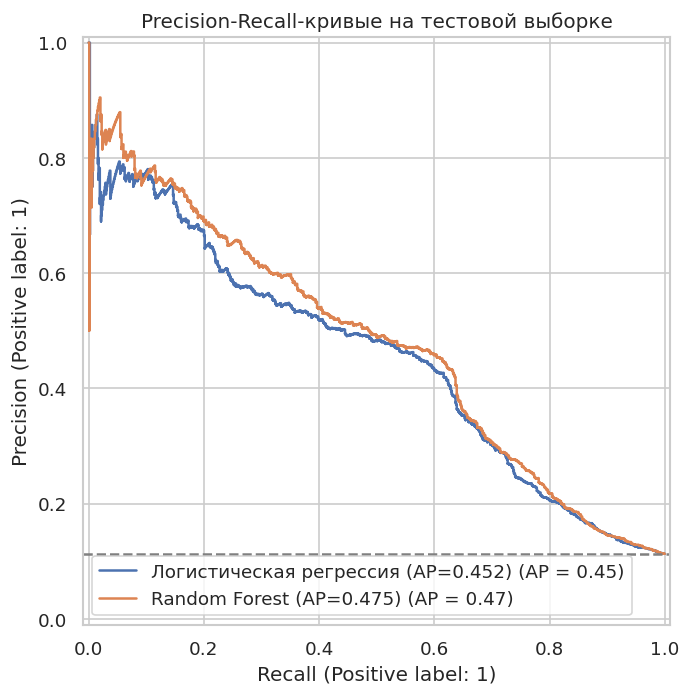

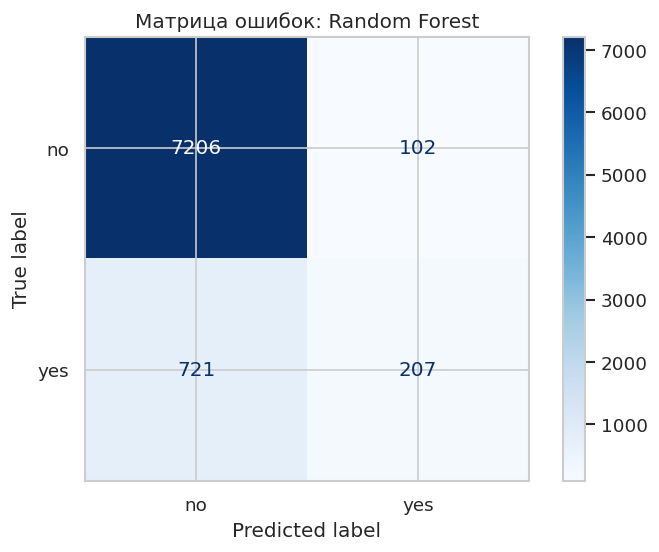

In [38]:
fig, ax = plt.subplots(figsize=(8, 6))
for name, probabilities in model_probabilities.items():
    PrecisionRecallDisplay.from_predictions(
        y_test,
        probabilities,
        name=f"{name} (AP={average_precision_score(y_test, probabilities):.3f})",
        ax=ax,
    )
ax.axhline(y_test.mean(), color="gray", linestyle="--", label="Доля yes")
ax.set_title("Precision-Recall-кривые на тестовой выборке")
plt.tight_layout()
plt.show()

best_model_name = cv_summary["PR-AUC среднее"].idxmax()
best_model = models[best_model_name]
best_prediction = model_predictions[best_model_name]
print("Лучшая по кросс-валидации модель:", best_model_name)
print(classification_report(
    y_test,
    best_prediction,
    labels=[0, 1],
    target_names=["no", "yes"],
    zero_division=0,
    digits=3,
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_prediction,
    labels=[0, 1],
    display_labels=["no", "yes"],
    cmap="Blues",
    values_format="d",
)
plt.title(f"Матрица ошибок: {best_model_name}")
plt.tight_layout()
plt.show()

В матрице ошибок строки соответствуют реальным ответам, столбцы - предсказаниям. Нижняя левая ячейка показывает клиентов с ответом "yes", которых модель пропустила; нижняя правая - клиентов, которых модель нашла. Так видны типы ошибок при выбранном пороге.

### 11.8. Какие признаки использует модель

Важность признаков Random Forest показывает, какие признаки чаще использовались при разделении данных. Она помогает сопоставить результат модели с EDA, но не доказывает, что признак сам по себе вызывает отклик.

Три самых важных признака:
num__euribor3m           0.213
cat__poutcome_success    0.152
num__nr.employed         0.130
dtype: float64


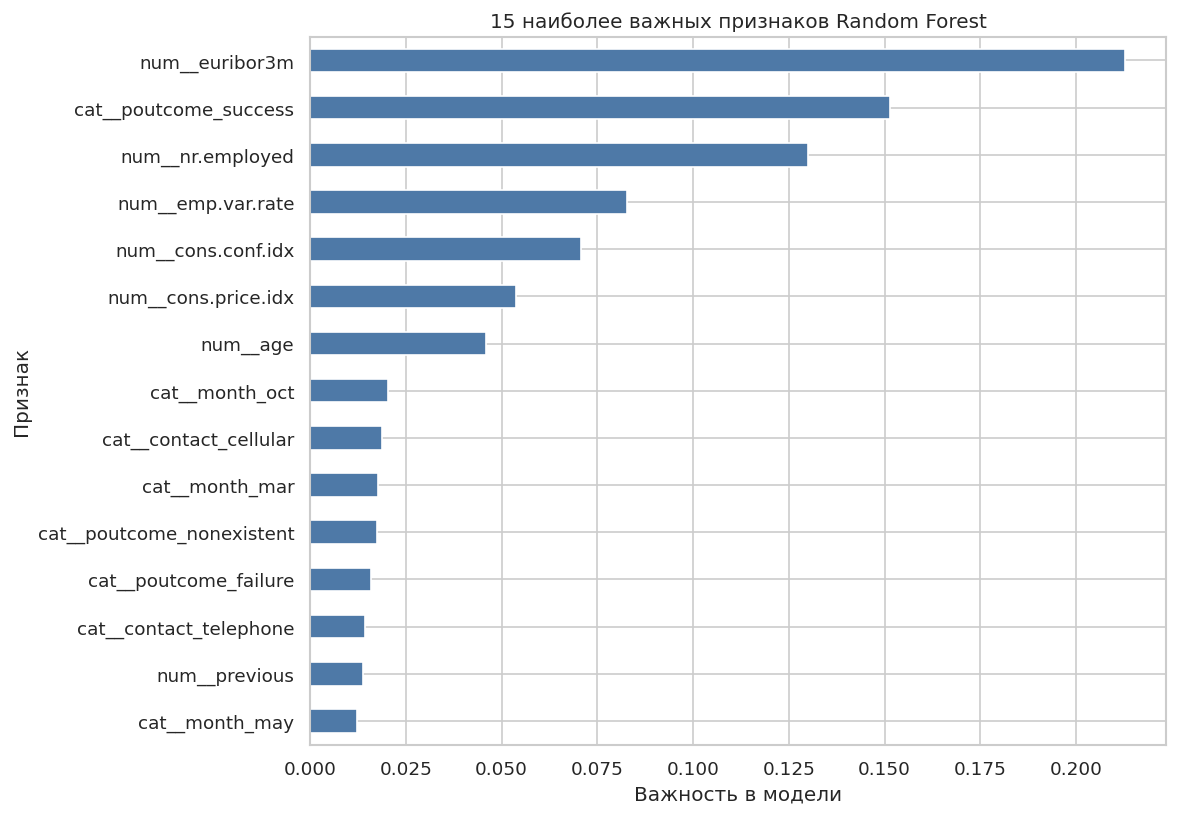

In [39]:
feature_names = random_forest_model.named_steps["preprocessor"].get_feature_names_out()
feature_importances = random_forest_model.named_steps["classifier"].feature_importances_
importance = pd.Series(feature_importances, index=feature_names).sort_values(ascending=False).head(15).sort_values()

ax = importance.plot(kind="barh", figsize=(10, 7), color=COLOR_MAIN)
ax.set_title("15 наиболее важных признаков Random Forest")
ax.set_xlabel("Важность в модели")
ax.set_ylabel("Признак")
plt.tight_layout()
plt.show()

print("Три самых важных признака:")
print(importance.sort_values(ascending=False).head(3).round(3))

### 11.9. Итоговые метрики

В одной ячейке собраны значения выбранной модели на кросс-валидации и тестовой выборке.

In [40]:
best_cv_mean = cv_summary.loc[best_model_name, "PR-AUC среднее"]
best_cv_std = cv_summary.loc[best_model_name, "PR-AUC стандартное отклонение"]
best_test = model_comparison.loc[best_model_name]

print(f"Выбранная модель: {best_model_name}")
print(f"PR-AUC на кросс-валидации: {best_cv_mean:.3f} +/- {best_cv_std:.3f}")
print(f"PR-AUC на тестовой выборке: {best_test['PR-AUC']:.3f}")
print(f"Precision для yes: {best_test['Precision yes']:.3f}")
print(f"Recall для yes: {best_test['Recall yes']:.3f}")
print(f"F1 для yes: {best_test['F1 yes']:.3f}")

Выбранная модель: Random Forest
PR-AUC на кросс-валидации: 0.462 +/- 0.013
PR-AUC на тестовой выборке: 0.475
Precision для yes: 0.670
Recall для yes: 0.223
F1 для yes: 0.335


# 12. Итог проекта

В проекте исследован отклик на предложение срочного вклада и построена модель, которая оценивает вероятность ответа "yes" по признакам, доступным до начала текущей кампании. Доля положительного класса составляет 11,3%, поэтому качество нельзя оценивать только по accuracy: важны также PR-AUC, precision и recall.

EDA показал различия отклика по каналу, месяцу, истории прошлых контактов и отдельным клиентским группам. Особенно заметна связь с результатом прошлой кампании: у клиентов с `poutcome = success` доля текущих ответов "yes" выше. Специальный код `pdays = 999` трактуется отдельно. `duration` и `campaign` остаются в описательном анализе, но не используются для прогноза до начала звонков, поскольку на этот момент они еще не известны.

Проверка новых признаков для `pdays` не дала заметного улучшения логистической регрессии на пяти фолдах, поэтому в итоговом сравнении используется более простой исходный набор признаков. Для логистической регрессии сравнение при одинаковых настройках показало более высокую среднюю PR-AUC с `StandardScaler` - 0,449 против 0,435 без масштабирования. При этом число коэффициентов осталось равным 60, а различие в их размерах связано с разными единицами измерения.

Лучший результат в проведенном сравнении показал Random Forest: средняя PR-AUC на обучающих фолдах равна 0,462 ± 0,013, PR-AUC на тестовой выборке - 0,475. На пороге 0,5 precision для "yes" составил 0,670, recall - 0,223, F1 - 0,335. Это означает, что среди выбранных моделью клиентов много ответивших положительно, но большая часть всех положительных ответов остается не найденной. Поэтому результат модели полезен для ранжирования аудитории, а практический порог зависит от того, что важнее в кампании - не пропустить потенциальный отклик или сократить число звонков без результата.